# Epithelial reintegration, specimen origin and CNV sensitivity

## Setup

In [1]:
import gc
import hashlib
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc
import anndata as ad
import infercnvpy as cnv
import scvi

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb
import logging


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: @rpath/R/lib/libR.dylib\n  Referenced from: <CBEF4F67-1D94-3EA0-88C4-F34EBE0600C2> /Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/si

In [ ]:
import os
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"#4 Nina 2 avoid kernel crashing

In [2]:
np.random.seed(0)
scvi.settings.seed = 0
scvi.settings.num_workers = 4

sc.settings.verbosity = 2
rcb.logger.setLevel(logging.ERROR)


Seed set to 0


In [3]:
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")

plt.rcParams.update({"font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "figure.dpi": 300})


In [4]:
target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]


In [5]:
random_seed = 0
n_hvg_primary = 4000
cnv_high_quantile = 0.95
infercnv_dynamic_threshold = 1.5 #package default
cnv_quantiles = (0.90, 0.95, 0.99)


In [6]:
n_latent = 20
n_layers = 2
gene_likelihood = "nb"
n_neighbors = 30
primary_resolution = 0.5
leiden_resolutions = (0.5, 1.0, 1.2, 1.5)


In [7]:
def find_project(start=None):
    here = Path(start or Path.cwd()).resolve()
    for parent in [here, *here.parents]:
        if (parent / "Data").is_dir() and (parent / "metadata").is_dir():
            return parent
    raise FileNotFoundError("Set CAP_PROJECT to the project data directory")


def find_publication():
    here = Path.cwd().resolve()
    for parent in [here, *here.parents]:
        for candidate in (parent, parent / "publication_notebooks"):
            if (candidate / "scripts" / "publication_figure_state.py").is_file():
                if (candidate / "data" / "cancer_meta_programme_signatures.xlsx").is_file():
                    return candidate
    raise FileNotFoundError("Run from the publication_notebooks directory")


In [8]:
#project = Path(os.environ.get("CAP_PROJECT") or find_project()).expanduser().resolve()
project  = Path(os.environ.get("CAP_PROJECT", "/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny")).expanduser()#4 Nina
data_dir = project / "Data"
fig_dir = project / "Figures"
df_dir = project / "Dataframe_Saves"
save_dir = project / "Adata_Saves"
model_dir = project / "scvi_epithelial_model"
notebook_dir = find_publication()


In [9]:
for d in [fig_dir, df_dir, save_dir, model_dir]:
    d.mkdir(parents=True, exist_ok=True)


In [10]:
sc.settings.figdir = fig_dir

meta_programme_file = notebook_dir / "data" / "cancer_meta_programme_signatures.xlsx"
#gencode_file = data_dir / "gencode.v50.annotation.gtf.gz"
gencode_file = data_dir / "gencode.v50.annotation.gtf"
source_tumour_file = (
    notebook_dir / "data"
    / "source_tumour_cluster_barcodes.csv.gz")


In [11]:
for path in [meta_programme_file, gencode_file, source_tumour_file]:
    assert path.exists(), path


In [12]:
source_tumour_sha256 = ("26af400ae38a5e878873c1cb30e83b8447440518a8727fdf7a8808d7780ede5c")
actual_source_tumour_sha256 = hashlib.sha256(
    source_tumour_file.read_bytes()
).hexdigest()
assert actual_source_tumour_sha256 == source_tumour_sha256

In [13]:
def rel(path):
    return Path(path).relative_to(project)

## Load the epithelial compartment

In [14]:
epi = sc.read_h5ad(save_dir / "epithelial.h5ad")


legacy_celltypist_columns = {
    "celltypist_pal_label": "celltypist_reference_label",
    "celltypist_pal_conf": "celltypist_reference_confidence",
}


In [15]:
epi.obs.rename(
    columns={
        old: new for old, new in legacy_celltypist_columns.items()
        if old in epi.obs.columns and new not in epi.obs.columns
    },
    inplace=True,
)


In [16]:
display(pd.DataFrame({
    "cells": [epi.n_obs],
    "genes": [epi.n_vars],
    "samples": [epi.obs["sample"].nunique()],
}))


,cells,genes,samples
0,129111,28538,44


In [17]:
# Keep the atlas coordinates from 002 before calculating the epithelial embedding.
if "X_umap" in epi.obsm and "X_umap_atlas" not in epi.obsm:
    epi.obsm["X_umap_atlas"] = epi.obsm["X_umap"].copy()


In [18]:
counts = epi.layers["counts"]
count_values = counts.data if sp.issparse(counts) else np.asarray(counts).ravel()

assert np.isfinite(count_values).all()
assert np.allclose(count_values, np.rint(count_values))

baseline_positive = {
    gene: int((np.asarray(epi[:, gene].layers["counts"].todense()).ravel() > 0).sum())
    for gene in target_genes
}
display(pd.Series(baseline_positive, name="cells_with_raw_count"))


ROR1      1171
ROR2      2674
EGFR     12771
ERBB2    36527
EPCAM    61847
Name: cells_with_raw_count, dtype: int64

## Gene filtering and normalisation

In [19]:
n_cells_loaded = epi.n_obs
n_genes_loaded = epi.n_vars


In [20]:
sc.pp.filter_genes(epi, min_cells=3)
n_genes_removed = n_genes_loaded - epi.n_vars


filtered out 1182 genes that are detected in less than 3 cells


In [21]:
n_cells_start = epi.n_obs
n_genes_start = epi.n_vars


In [22]:
shape_summary = pd.DataFrame({
    "stage": ["loaded", "analysis object"],
    "cells": [n_cells_loaded, epi.n_obs],
    "genes": [n_genes_loaded, epi.n_vars],
})
display(shape_summary)


,stage,cells,genes
0,loaded,129111,28538
1,analysis object,129111,27356


In [23]:
epi.layers["lognorm"] = epi.layers["log1p"].copy()
epi.X = epi.layers["lognorm"].copy()


In [24]:
# the master shape that must survive inferCNV, scVI and clustering unchanged
n_cells_start = epi.n_obs
n_genes_start = epi.n_vars

assert n_cells_start == n_cells_loaded
assert n_genes_start == n_genes_loaded - n_genes_removed


## Highly variable genes



Binomial deviance (`scry`) computed per sample and aggregated by the maximum
across samples, so that a gene deviant in a single condition is retained.
Mitochondrial, ribosomal and haemoglobin genes are excluded before ranking.
Cell-cycle genes are deliberately **not** excluded here: proliferation is a
tumour-associated epithelial state of interest.

In [25]:
%load_ext rpy2.ipython


In [26]:
%%R
suppressPackageStartupMessages({
    library(Matrix)
    library(SingleCellExperiment)
    library(scry)
})


In [27]:
def scipy_to_dgc(matrix):
    # transfer a scipy sparse matrix to R as a dgCMatrix
    matrix = sp.csc_matrix(matrix)
    return ro.r["new"](
        "dgCMatrix",
        i=ro.IntVector(matrix.indices),
        p=ro.IntVector(matrix.indptr),
        x=ro.FloatVector(matrix.data),
        Dim=ro.IntVector(matrix.shape),
    )


In [28]:
samples = epi.obs["sample"].astype(str).unique().tolist()

deviance = pd.DataFrame(index=epi.var_names, columns=samples, dtype=float)


In [29]:
for sample in samples:

    sub = epi[epi.obs["sample"].astype(str) == sample]

    ro.globalenv["raw_counts"] = scipy_to_dgc(sub.layers["counts"].T)
    ro.globalenv["gene_names"] = ro.StrVector(sub.var_names.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(sub.obs_names.tolist())

    ro.r('''
        rownames(raw_counts) <- gene_names
        colnames(raw_counts) <- cell_names

        sce <- SingleCellExperiment(assays = list(counts = raw_counts))
        sce <- devianceFeatureSelection(sce)

        binomial_deviance <- rowData(sce)$binomial_deviance
    ''')

    deviance[sample] = np.asarray(ro.r["binomial_deviance"])
    ro.r("rm(raw_counts, sce, binomial_deviance); gc()")
    print(f"{sample}: {sub.n_obs:,} cells")


GSM4909253_N-PM0092-Total: 3,156 cells
GSM4909254_N-PM0019-Total: 3,831 cells
GSM4909257_N-PM0095-Total: 2,221 cells
GSM4909261_N-PM0230-Total: 815 cells
GSM4909263_N-MH0064-Total: 715 cells
GSM4909265_N-PM0233-Total: 2,048 cells
GSM4909266_N-MH0169-Total: 724 cells
GSM4909268_N-MH0023-Total: 4,071 cells
GSM4909270_N-PM0342-Total: 4,361 cells
GSM4909272_N-MH0021-Total: 1,232 cells
GSM4909274_N-MH275-Total: 825 cells
GSM4909276_N-PM0372-Total: 1,683 cells
GSM4909281_TN-MH0126: 1,079 cells
GSM4909282_TN-MH0135: 12,289 cells
GSM4909283_TN-SH0106: 58 cells
GSM4909284_TN-MH0114-T2: 158 cells
GSM4909285_TN-B1-MH4031: 4,707 cells
GSM4909286_TN-B1-MH0131: 4,864 cells
GSM4909287_TN-B1-Tum0554: 2,866 cells
GSM4909288_TN-B1-MH0177: 883 cells
GSM4909289_HER2-AH0308: 2,996 cells
GSM4909290_HER2-PM0337: 2,985 cells
GSM4909291_HER2-MH0031: 1,449 cells
GSM4909292_HER2-MH0069: 239 cells
GSM4909293_HER2-MH0161: 3,855 cells
GSM4909294_HER2-MH0176: 5,009 cells
GSM4909295_ER-AH0319: 563 cells
GSM4909296_ER

In [30]:
epi.var["binomial_deviance"] = deviance.max(axis=1)

assert epi.var["binomial_deviance"].notna().all()


In [31]:
for column in ["mt", "ribo", "hb"]:
    assert column in epi.var.columns, column

exclude = epi.var[["mt", "ribo", "hb"]].any(axis=1)


In [32]:
ranked = (
    epi.var.loc[~exclude, "binomial_deviance"]
    .sort_values(ascending=False)
    .index
)

deviant_genes = ranked[:n_hvg_primary]


In [33]:
# These genes are tracked for a sensitivity model, but do not enter the primary model unless selected by deviance.
meta_programme_sheet = pd.read_excel(meta_programme_file, sheet_name="Cancer MPs")
meta_programme_genes = (
    meta_programme_sheet.stack().dropna().astype(str).str.strip().loc[lambda x: x.ne("")].unique()
)


In [34]:
protected = sorted(set(target_genes) | set(meta_programme_genes))
protected_present = [gene for gene in protected if gene in epi.var_names]


In [35]:
epi.var["highly_variable_deviance"] = epi.var_names.isin(deviant_genes)
epi.var["highly_variable_protected"] = (
    epi.var["highly_variable_deviance"] | epi.var_names.isin(protected_present)
)

# The primary embedding is independent of the antigen and meta-programme lists.
epi.var["highly_variable"] = epi.var["highly_variable_deviance"].copy()

n_hvg_deviance = int(epi.var["highly_variable_deviance"].sum())
n_hvg_protected = int(epi.var["highly_variable_protected"].sum())
n_protected_added = n_hvg_protected - n_hvg_deviance


In [36]:
hvg_summary = pd.DataFrame({
    "feature_set": ["primary_deviance", "protected_sensitivity"],
    "n_genes": [n_hvg_deviance, n_hvg_protected],
})
display(hvg_summary)

pd.Series(deviant_genes, name="gene").to_csv(
    df_dir / "epithelial_hvg_genes.csv", index=False
)


,feature_set,n_genes
0,primary_deviance,4000
1,protected_sensitivity,4588


## inferCNV


Run inferCNV on a separate object so its gene filtering cannot alter the integration object. Genomic coordinates come from GENCODE v50 and are joined by stable Ensembl gene ID. The primary run uses infercnvpy's documented default dynamic threshold of 1.5. The normal-reference quantile sensitivity below does not test this smoothing parameter.

In [37]:
# inferCNV needs log-normalised expression, the sample annotation and the gene coordinates. A full epi.copy() would also carry the counts layer and double peak memory for no benefit, so the working object is built slim.
cnv_adata = ad.AnnData(
    X=epi.layers["lognorm"].copy(),
    obs=epi.obs.copy(),
    var=epi.var.copy(),
)

print(f"inferCNV working object: {cnv_adata.n_obs:,} cells x {cnv_adata.n_vars:,} genes")


inferCNV working object: 129,111 cells x 27,356 genes


In [38]:
gtf = pd.read_csv(
    gencode_file,
    sep="\t",
    comment="#",
    header=None,
    names=["chromosome", "source", "feature", "start", "end",
           "score", "strand", "frame", "attribute"],
)


In [39]:
gencode = gtf[gtf["feature"] == "gene"].copy()


In [40]:
gencode["ensembl"] = (
    gencode["attribute"].str.extract(r'gene_id "([^"]+)"')[0].str.split(".").str[0]
)


In [41]:
gencode["gene_type"] = gencode["attribute"].str.extract(r'gene_type "([^"]+)"')[0]


In [42]:
gencode = gencode.drop_duplicates("ensembl").set_index("ensembl")


In [43]:
len(gencode)


86411

In [44]:
del gtf
gc.collect()


43

In [45]:
# join on stable Ensembl identifiers taken from the dataset's own annotation
ensembl = cnv_adata.var["gene_id"].astype(str).str.split(".").str[0]


In [46]:
cnv_adata.var["chromosome"] = ensembl.map(gencode["chromosome"]).values
cnv_adata.var["start"] = ensembl.map(gencode["start"]).values
cnv_adata.var["end"] = ensembl.map(gencode["end"]).values
cnv_adata.var["gene_type"] = ensembl.map(gencode["gene_type"]).values

resolved = cnv_adata.var["chromosome"].notna()


In [47]:
del gencode
gc.collect()


28

In [48]:
resolved.sum(), cnv_adata.n_vars


(np.int64(26550), 27356)

In [49]:
cnv_adata.var.loc[~resolved, ["gene_id"]].to_csv(df_dir / "infercnv_unresolved_genes.csv")


In [50]:
# protein-coding autosomal genes only


In [51]:
autosomes = [f"chr{i}" for i in range(1, 23)]

keep = (
    cnv_adata.var["chromosome"].isin(autosomes)
    & cnv_adata.var["gene_type"].eq("protein_coding")
)


In [52]:
cnv_adata = cnv_adata[:, keep].copy()


In [53]:
cnv_adata.n_vars


17499

In [54]:
# gene families whose variation is not driven by copy number
problematic = (
    cnv_adata.var_names.str.startswith(
        ("MT-", "RPS", "RPL", "HLA-", "IGH", "IGK", "IGL", "KRT", "SPRR", "S100A")
    )
    | cnv_adata.var_names.isin(["MALAT1", "NEAT1"])
)


In [55]:
problematic.sum()


np.int64(230)

In [56]:
cnv_adata = cnv_adata[:, ~problematic].copy()


In [57]:
sc.pp.filter_genes(cnv_adata, min_cells=100)


filtered out 2368 genes that are detected in less than 100 cells


In [58]:
cnv_adata.n_vars


14901

In [59]:
# genomic ordering
cnv_adata.var["chromosome"] = cnv_adata.var["chromosome"].astype(str)
cnv_adata.var["chr_num"] = cnv_adata.var["chromosome"].str.replace("chr", "", regex=False).astype(int)

order = cnv_adata.var.sort_values(["chr_num", "start"]).index
cnv_adata = cnv_adata[:, order].copy()

assert cnv_adata.var_names.is_unique
assert (np.diff(cnv_adata.var["chr_num"].to_numpy()) >= 0).all()


In [60]:
# normal epithelium provides the diploid reference
reference = cnv_adata[cnv_adata.obs["condition"] == "N"].copy()

print(f"reference cells: {reference.n_obs:,} from {reference.obs['sample'].nunique()} samples")


reference cells: 25,682 from 12 samples


In [61]:
cnv_adata.obs["cnv_score"] = np.nan
cnv_adata.obs["cnv_signal"] = np.nan

x_cnv_full = None
failures = []

cnv_samples = cnv_adata.obs["sample"].astype(str).unique().tolist()


In [62]:
len(cnv_samples)


44

In [63]:
for sample in cnv_samples:

    print(f"\n{sample}")

    target = refs = combined = None

    try:
        target = cnv_adata[cnv_adata.obs["sample"].astype(str) == sample].copy()
        condition = str(target.obs["condition"].iloc[0])

        # a normal sample is never its own reference
        if condition == "N":
            refs = reference[reference.obs["sample"].astype(str) != sample].copy()
        else:
            refs = reference.copy()

        assert refs.n_obs > 0

        refs.obs["cnv_reference"] = "reference"
        target.obs["cnv_reference"] = "query"

        combined = sc.concat([refs, target], join="inner", merge="same")

        print(f"  {condition}: {target.n_obs:,} query, {refs.n_obs:,} reference")

        # X holds log-normalised expression, so no layer is passed
        cnv.tl.infercnv(
            combined,
            reference_key="cnv_reference",
            reference_cat=["reference"],
            window_size=100,
            step=10,
            dynamic_threshold=infercnv_dynamic_threshold,
            exclude_chromosomes=("chrX", "chrY"),
            n_jobs=1,
        )

        x_cnv = combined.obsm["X_cnv"]
        x_cnv = x_cnv.toarray() if sp.issparse(x_cnv) else np.asarray(x_cnv)
        x_cnv = x_cnv.astype(np.float32)

        query = combined.obs["cnv_reference"].eq("query").to_numpy()
        query_names = combined.obs_names[query]
        x_query = x_cnv[query]

        # map each inferCNV window to its chromosome
        chr_pos = sorted(combined.uns["cnv"]["chr_pos"].items(), key=lambda kv: kv[1])
        n_windows = x_query.shape[1]

        chr_labels = np.empty(n_windows, dtype=object)

        for i, (chrom, start) in enumerate(chr_pos):
            end = chr_pos[i + 1][1] if i + 1 < len(chr_pos) else n_windows
            chr_labels[start:end] = chrom

        # Chromosome RMS burden weighted by window count; chromosomes with more windows receive more weight.
        chrom_scores = []
        chrom_weights = []

        for chrom in pd.unique(chr_labels):
            idx = np.flatnonzero(chr_labels == chrom)
            chrom_scores.append(np.sqrt(np.mean(x_query[:, idx] ** 2, axis=1)))
            chrom_weights.append(len(idx))

        chrom_scores = np.column_stack(chrom_scores)
        chrom_weights = np.asarray(chrom_weights, dtype=float)
        chrom_weights /= chrom_weights.sum()

        cnv_score = np.average(chrom_scores, axis=1, weights=chrom_weights)
        cnv_signal = np.max(np.abs(x_query), axis=1)

        cnv_adata.obs.loc[query_names, "cnv_score"] = cnv_score
        cnv_adata.obs.loc[query_names, "cnv_signal"] = cnv_signal

        if x_cnv_full is None:
            x_cnv_full = np.full((cnv_adata.n_obs, n_windows), np.nan, dtype=np.float32)

        if "cnv" not in cnv_adata.uns:
            cnv_adata.uns["cnv"] = dict(combined.uns["cnv"])

        x_cnv_full[cnv_adata.obs_names.get_indexer(query_names)] = x_query

        print(f"  median burden {np.median(cnv_score):.4f}")

    except Exception as error:
        print(f"  failed: {error}")
        failures.append({"sample": sample, "error": str(error)})

    finally:
        del target, refs, combined
        gc.collect()



GSM4909253_N-PM0092-Total
  N: 3,156 query, 22,526 reference


100%|██████████| 6/6 [00:21<00:00,  3.60s/it]


  median burden 0.0248

GSM4909254_N-PM0019-Total
  N: 3,831 query, 21,851 reference


100%|██████████| 6/6 [00:21<00:00,  3.56s/it]


  median burden 0.0258

GSM4909257_N-PM0095-Total
  N: 2,221 query, 23,461 reference


...

  median burden 0.0356

GSM4909315_ER-MH0167-T
  ER+: 4,803 query, 25,682 reference


100%|██████████| 7/7 [00:23<00:00,  3.42s/it]


  median burden 0.0359

GSM4909317_ER-MH0173-T
  ER+: 2,625 query, 25,682 reference


100%|██████████| 6/6 [00:22<00:00,  3.70s/it]


  median burden 0.0407


In [64]:
# Missing inferCNV results must never pass silently into downstream calls.
failures = pd.DataFrame(failures)

if not failures.empty:
    failures.to_csv(df_dir / "infercnv_failed_samples.csv", index=False)
    raise RuntimeError(f"inferCNV failed for {len(failures)} sample(s)")

assert cnv_adata.obs[["cnv_score", "cnv_signal"]].notna().all().all()

display(pd.DataFrame({"infercnv_samples_completed": [len(cnv_samples)]}))


,infercnv_samples_completed
0,44


In [65]:
valid = cnv_adata.obs[["cnv_score", "total_counts"]].dropna()
r = np.corrcoef(valid["cnv_score"], valid["total_counts"])[0, 1]
display(pd.DataFrame({"cnv_score_vs_total_counts_r": [r]}).round(3))


,cnv_score_vs_total_counts_r
0,-0.249


In [66]:
cnv_adata.obs.groupby("condition", observed=True)["cnv_score"].describe().round(4)


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
N,25682.0,0.0257,0.0102,0.0005,0.0179,0.0270,0.0333,0.0654
TN,26904.0,0.0371,0.0094,0.0000,0.0309,0.0373,0.0435,0.1645
HER2+,16533.0,0.0353,0.0080,0.0033,0.0301,0.0351,0.0402,0.1006
ER+,59992.0,0.0344,0.0071,0.0011,0.0302,0.0345,0.0387,0.0906


## Specimen origin and CNV-high sensitivity



The primary population definition follows specimen origin. Epithelial cells
from ER+, HER2+ and TN specimens are labelled `tumour_derived`; this does not
imply that every cell is malignant. Normal-tissue epithelial cells provide the
reference population.

`cnv_high` is a technical flag applied to every epithelial cell whose inferred
CNV burden exceeds the 95th percentile of normal epithelium. The conjunction
of tumour origin and this flag is stored as `tumour_derived_cnv_high`. This is a
conservative CNV-enriched subgroup, not a classification of every tumour-derived cell.

Released tumour-cluster barcodes are retained only as an external concordance
variable. G1-restricted summaries assess whether cell-cycle transcription
materially affects the CNV-high sensitivity analysis.


In [67]:
condition_values = cnv_adata.obs["condition"].astype(str)
phase_values = cnv_adata.obs["phase"].astype(str)

normal_mask = condition_values.eq("N")
normal_scores = cnv_adata.obs.loc[normal_mask, "cnv_score"]
normal_g1_scores = cnv_adata.obs.loc[
    normal_mask & phase_values.eq("G1"), "cnv_score"
]

cnv_high_threshold = float(normal_scores.quantile(cnv_high_quantile))
cnv_high_threshold_g1 = float(normal_g1_scores.quantile(cnv_high_quantile))

source_tumour = pd.read_csv(
    source_tumour_file,
    dtype={"sample_code": str, "barcode": str},
)
required_columns = {"condition", "sample_code", "barcode", "source_cluster"}
assert required_columns.issubset(source_tumour.columns)


In [68]:
assert not source_tumour.duplicated(
    ["condition", "sample_code", "barcode"]
).any()


In [69]:
def sample_code(sample):
    sample_name = str(sample).split("_", 1)[-1]
    matches = re.findall(r"(?<!\d)(\d{4})(?!\d)", sample_name)
    return matches[-1] if matches else ""


In [70]:
condition_values = cnv_adata.obs["condition"].astype(str)
sample_codes = cnv_adata.obs["sample"].astype(str).map(sample_code)
cell_barcodes = cnv_adata.obs_names.to_series().str.split("-GSM").str[0]

source_keys = set(source_tumour[
    ["condition", "sample_code", "barcode"]
].itertuples(index=False, name=None))
available_groups = set(source_tumour[
    ["condition", "sample_code"]
].drop_duplicates().itertuples(index=False, name=None))

cell_keys = zip(condition_values, sample_codes, cell_barcodes)


In [71]:
sample_keys = zip(condition_values, sample_codes)

cnv_adata.obs["source_tumour_cluster"] = np.fromiter(
    (key in source_keys for key in cell_keys), dtype=bool, count=cnv_adata.n_obs
)
cnv_adata.obs["source_tumour_cluster_eligible"] = np.fromiter(
    (key in available_groups for key in sample_keys),
    dtype=bool,
    count=cnv_adata.n_obs,
)

# Source sample identity must be supported before any barcode transfer.#
#transfer_exclusions = pd.read_csv(
#    notebook_dir / "data" / "source_transfer_exclusions.csv"
#)
#not_transferable = cnv_adata.obs["sample"].astype(str).isin(transfer_exclusions["sample"])
#cnv_adata.obs.loc[not_transferable, "source_tumour_cluster"] = False
#cnv_adata.obs.loc[not_transferable, "source_tumour_cluster_eligible"] = False


In [72]:
cnv_adata.obs["tumour_derived"] = condition_values.ne("N")
cnv_adata.obs["cnv_high"] = cnv_adata.obs["cnv_score"].gt(
    cnv_high_threshold
)
cnv_adata.obs["tumour_derived_cnv_high"] = (
    cnv_adata.obs["tumour_derived"] & cnv_adata.obs["cnv_high"]
)
cnv_adata.obs["g1_cell"] = phase_values.eq("G1")
cnv_adata.obs["tumour_derived_cnv_high_g1"] = (
    cnv_adata.obs["tumour_derived_cnv_high"] & cnv_adata.obs["g1_cell"]
)


In [73]:
origin_call = np.where(
    condition_values.eq("N"),
    "normal-tissue epithelium",
    "tumour-derived epithelium",
)
origin_order = ["normal-tissue epithelium", "tumour-derived epithelium"]

source_call = np.full(cnv_adata.n_obs, "not evaluated", dtype=object)
normal = condition_values.eq("N").to_numpy()
eligible = cnv_adata.obs["source_tumour_cluster_eligible"].to_numpy()
source_tumour_mask = cnv_adata.obs["source_tumour_cluster"].to_numpy()

source_call[normal] = "normal reference"
source_call[eligible] = "other epithelial"
source_call[source_tumour_mask] = "source tumour cluster"
source_call_order = [
    "normal reference", "source tumour cluster", "other epithelial",
    "not evaluated",
]


In [74]:
cnv_adata.obs["specimen_origin"] = pd.Categorical(
    origin_call, categories=origin_order
)
cnv_adata.obs["source_tumour_cluster_call"] = pd.Categorical(
    source_call, categories=source_call_order
)

population_counts = pd.crosstab(
    cnv_adata.obs["condition"], cnv_adata.obs["specimen_origin"], margins=True
)


In [75]:
display(population_counts)


specimen_origin,normal-tissue epithelium,tumour-derived epithelium,All
condition,,,
N,25682,0,25682
TN,0,26904,26904
HER2+,0,16533,16533
ER+,0,59992,59992
All,25682,103429,129111


In [76]:
rows = []


In [77]:
for quantile in cnv_quantiles:
    threshold = float(normal_scores.quantile(quantile))
    called = (
        cnv_adata.obs["cnv_score"].gt(threshold)
        & cnv_adata.obs["condition"].ne("N")
    )

    for condition in ["ER+", "HER2+", "TN"]:
        mask = cnv_adata.obs["condition"].eq(condition)
        rows.append({
            "normal_quantile": quantile,
            "threshold": threshold,
            "condition": condition,
            "n_cells": int(mask.sum()),
            "n_cnv_high": int(called[mask].sum()),
            "cnv_high_fraction": float(called[mask].mean()),
        })


In [78]:
threshold_sensitivity = pd.DataFrame(rows)
threshold_sensitivity.to_csv(
    df_dir / "infercnv_threshold_sensitivity.csv", index=False
)
display(threshold_sensitivity.round(4))


,normal_quantile,threshold,condition,n_cells,n_cnv_high,cnv_high_fraction
0,0.90,0.0380,ER+,59992,17254,0.2876
1,0.90,0.0380,HER2+,16533,5736,0.3469
2,0.90,0.0380,TN,26904,12700,0.4720
3,0.95,0.0410,ER+,59992,9453,0.1576
4,0.95,0.0410,HER2+,16533,3598,0.2176
5,0.95,0.0410,TN,26904,9276,0.3448
6,0.99,0.0471,ER+,59992,2168,0.0361
7,0.99,0.0471,HER2+,16533,1148,0.0694
8,0.99,0.0471,TN,26904,3754,0.1395


In [79]:
cycle_cnv_summary = (
    cnv_adata.obs
    .groupby(["condition", "phase"], observed=True)
    .agg(
        n_cells=("cnv_score", "size"),
        median_cnv=("cnv_score", "median"),
        cnv_high_fraction=("cnv_high", "mean"),
        tumour_derived_cnv_high_fraction=("tumour_derived_cnv_high", "mean"),
    )
    .reset_index()
)
cycle_cnv_summary["normal_all_q95"] = cnv_high_threshold
cycle_cnv_summary["normal_g1_q95"] = cnv_high_threshold_g1
cycle_cnv_summary.to_csv(
    df_dir / "infercnv_cell_cycle_sensitivity.csv", index=False
)
display(cycle_cnv_summary.round(4))


,condition,phase,n_cells,median_cnv,cnv_high_fraction,tumour_derived_cnv_high_fraction,normal_all_q95,normal_g1_q95
0,N,G1,19423,0.0253,0.0407,0.0000,0.041,0.0401
1,N,G2M,3531,0.0308,0.0711,0.0000,0.041,0.0401
2,N,S,2728,0.0316,0.0894,0.0000,0.041,0.0401
3,TN,G1,13725,0.0339,0.2092,0.2092,0.041,0.0401
4,TN,G2M,6255,0.0423,0.5637,0.5637,0.041,0.0401
5,TN,S,6924,0.0393,0.4158,0.4158,0.041,0.0401
6,HER2+,G1,12304,0.0348,0.2047,0.2047,0.041,0.0401
7,HER2+,G2M,1443,0.0365,0.2730,0.2730,0.041,0.0401
8,HER2+,S,2786,0.0358,0.2459,0.2459,0.041,0.0401
9,ER+,G1,37535,0.0343,0.1500,0.1500,0.041,0.0401


In [80]:
sample_population_summary = (
    cnv_adata.obs
    .groupby(["sample", "condition"], observed=True)
    .agg(
        n_epithelial_cells=("tumour_derived", "size"),
        n_tumour_derived=("tumour_derived", "sum"),
        n_cnv_high=("cnv_high", "sum"),
        n_tumour_derived_cnv_high=("tumour_derived_cnv_high", "sum"),
        n_tumour_derived_cnv_high_g1=("tumour_derived_cnv_high_g1", "sum"),
        n_source_tumour_cluster=("source_tumour_cluster", "sum"),
        median_cnv=("cnv_score", "median"),
    )
    .reset_index()
)


In [81]:
sample_population_summary["tumour_derived_cnv_high_fraction"] = (
    sample_population_summary["n_tumour_derived_cnv_high"]
    / sample_population_summary["n_epithelial_cells"]
)
sample_population_summary["tumour_derived_cnv_high_g1_fraction"] = (
    sample_population_summary["n_tumour_derived_cnv_high_g1"]
    / sample_population_summary["n_epithelial_cells"]
)
sample_population_summary["source_tumour_cluster_fraction"] = (
    sample_population_summary["n_source_tumour_cluster"]
    / sample_population_summary["n_epithelial_cells"]
)


In [82]:
sample_population_summary.sort_values(
    ["condition", "tumour_derived_cnv_high_fraction"]
).round(3)


,sample,condition,n_epithelial_cells,n_tumour_derived,n_cnv_high,n_tumour_derived_cnv_high,n_tumour_derived_cnv_high_g1,n_source_tumour_cluster,median_cnv,tumour_derived_cnv_high_fraction,tumour_derived_cnv_high_g1_fraction,source_tumour_cluster_fraction
0,GSM4909253_N-PM0092-Total,N,3156,0,43,0,0,0,0.025,0.000,0.000,0.000
1,GSM4909254_N-PM0019-Total,N,3831,0,268,0,0,0,0.026,0.000,0.000,0.000
2,GSM4909257_N-PM0095-Total,N,2221,0,115,0,0,0,0.020,0.000,0.000,0.000
3,GSM4909261_N-PM0230-Total,N,815,0,43,0,0,0,0.024,0.000,0.000,0.000
4,GSM4909263_N-MH0064-Total,N,715,0,32,0,0,0,0.029,0.000,0.000,0.000
5,GSM4909265_N-PM0233-Total,N,2048,0,91,0,0,0,0.024,0.000,0.000,0.000
6,GSM4909266_N-MH0169-Total,N,724,0,46,0,0,0,0.028,0.000,0.000,0.000
7,GSM4909268_N-MH0023-Total,N,4071,0,227,0,0,0,0.029,0.000,0.000,0.000
8,GSM4909270_N-PM0342-Total,N,4361,0,257,0,0,0,0.030,0.000,0.000,0.000
9,GSM4909272_N-MH0021-Total,N,1232,0,35,0,0,0,0.033,0.000,0.000,0.000


In [83]:
sample_population_summary.to_csv(
    df_dir / "epithelial_population_summary_by_sample.csv", index=False
)


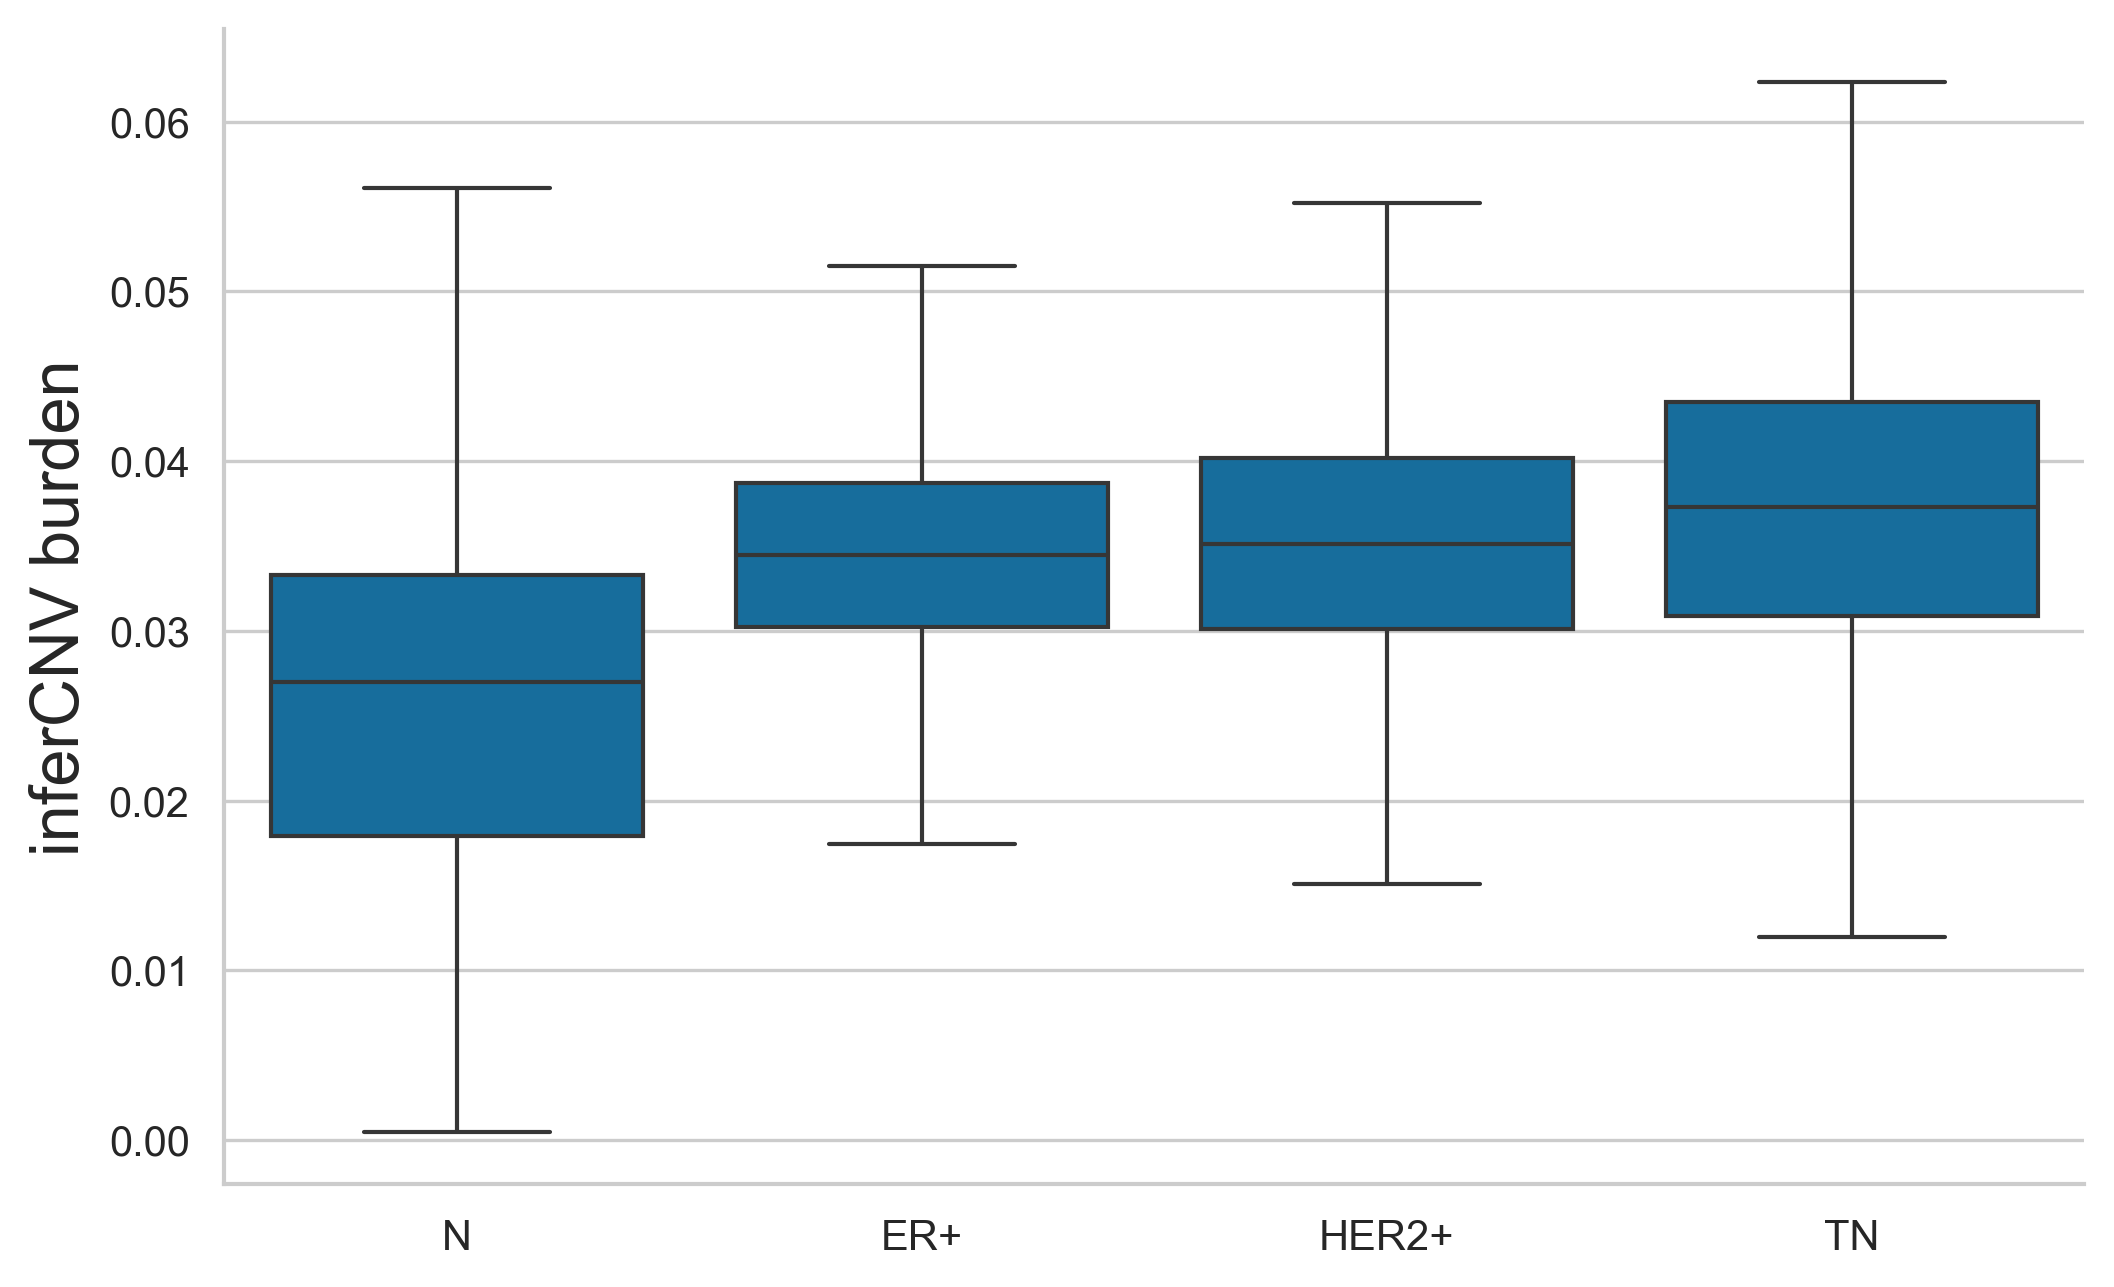

In [84]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=cnv_adata.obs,
    x="condition",
    y="cnv_score",
    order=["N", "ER+", "HER2+", "TN"],
    showfliers=False,
    ax=ax,
)

ax.set_xlabel("")


ax.set_ylabel("inferCNV burden")
sns.despine()

plt.savefig(fig_dir / "infercnv_score_by_condition.png", dpi=300, bbox_inches="tight")
plt.show()


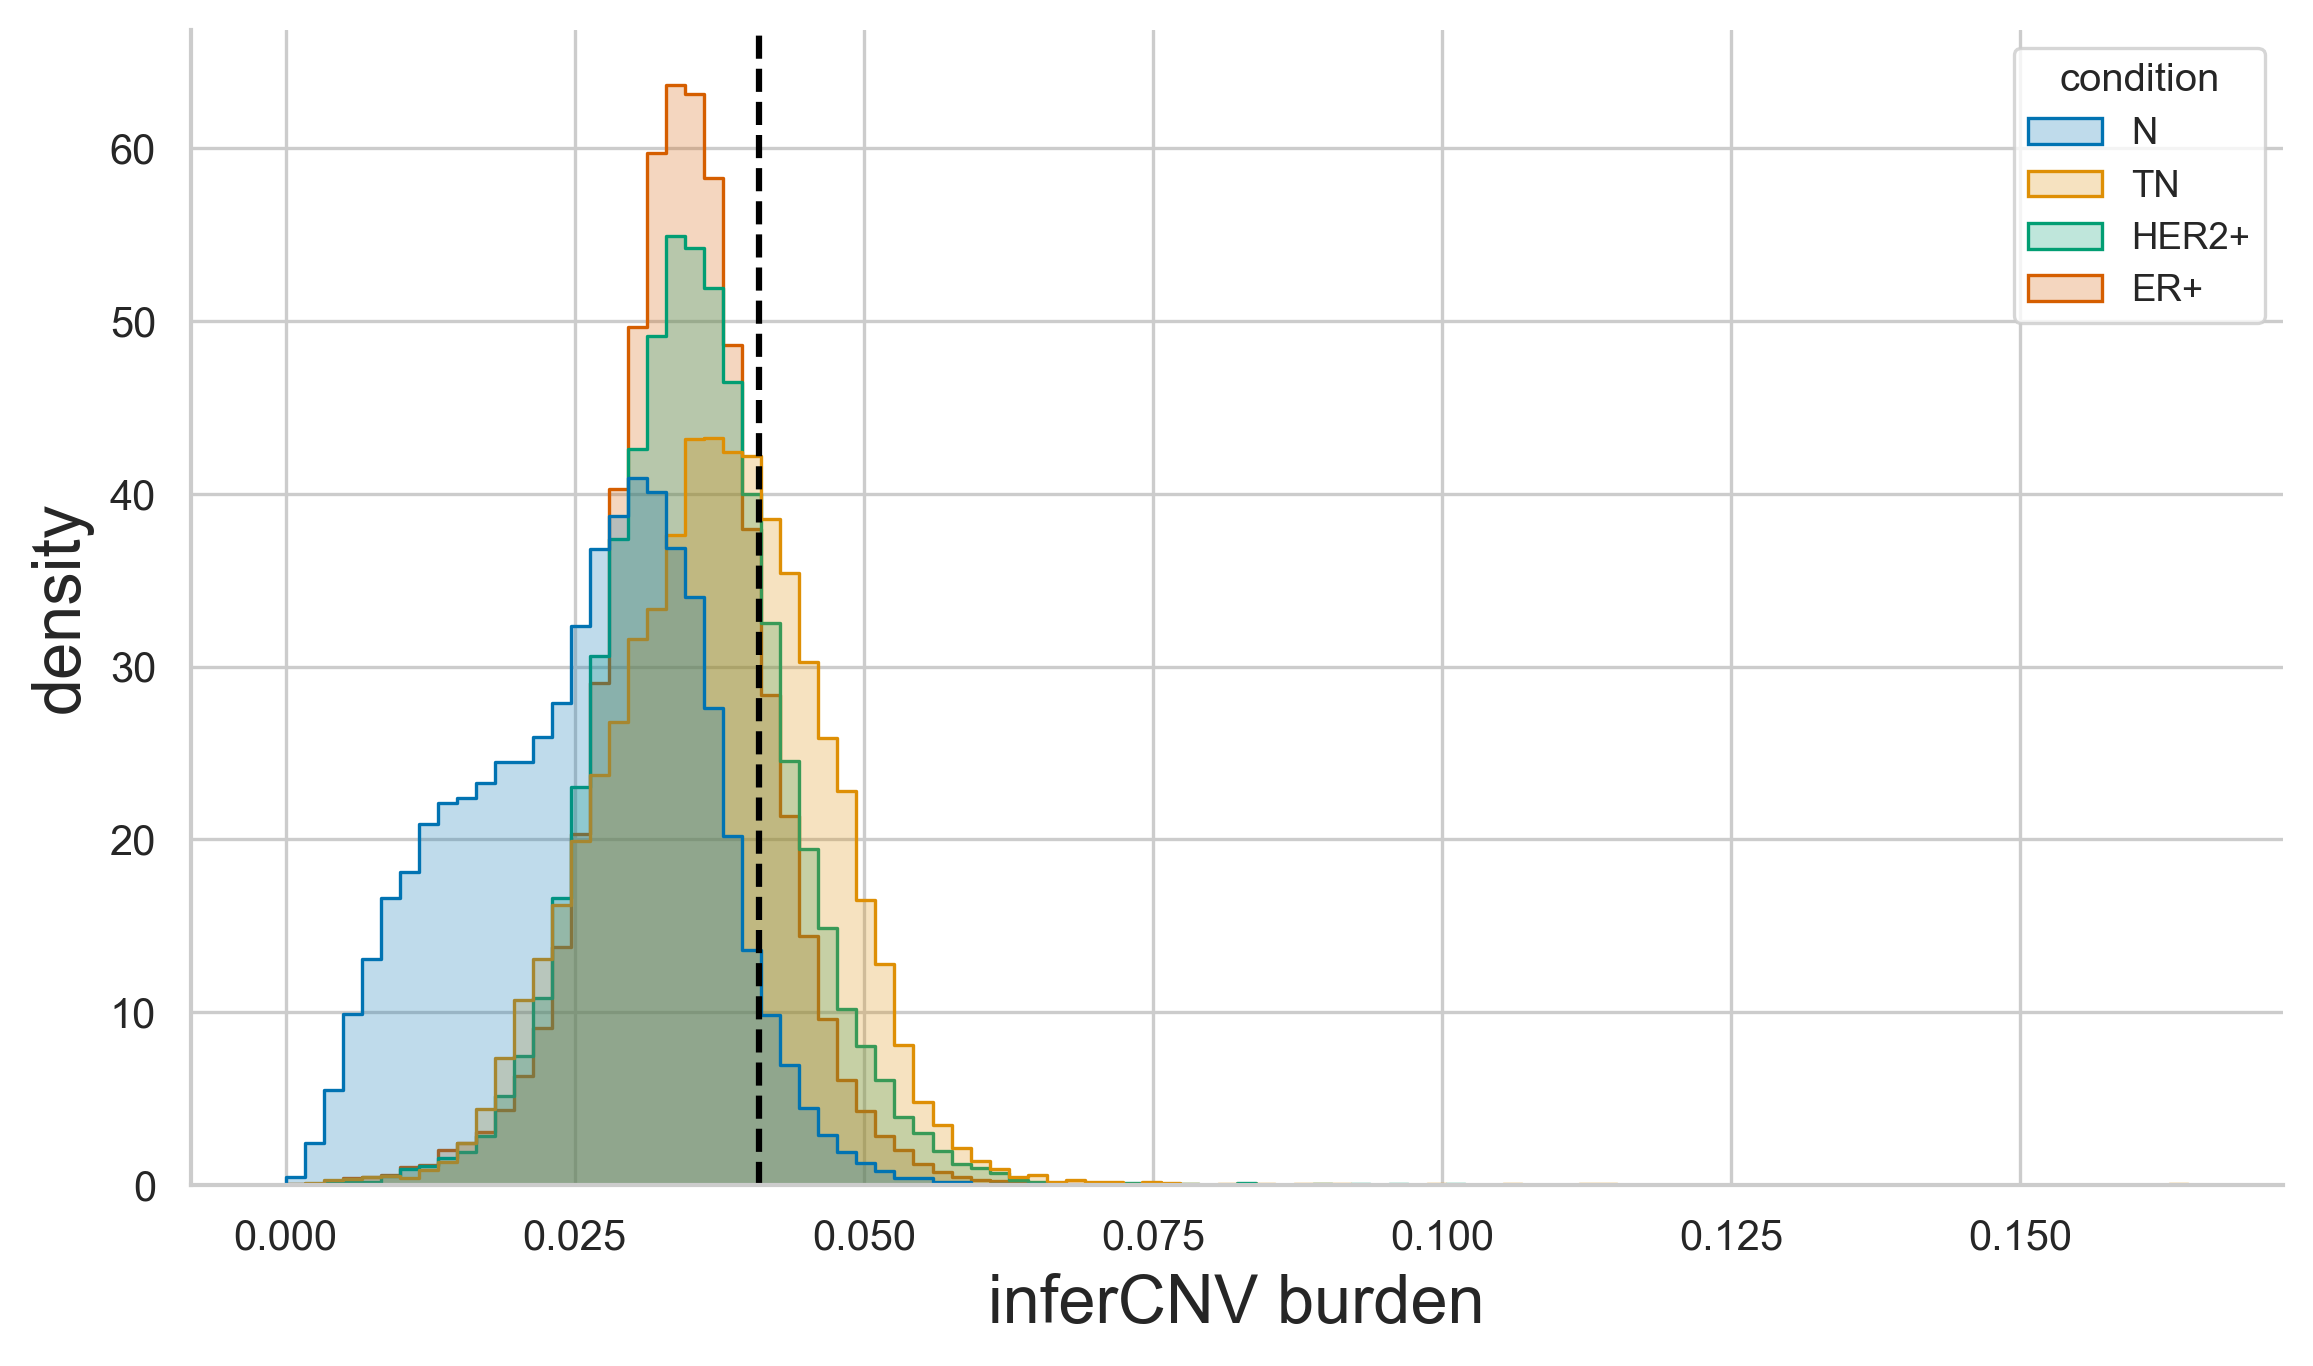

In [85]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=cnv_adata.obs,
    x="cnv_score",
    hue="condition",
    bins=100,
    stat="density",
    common_norm=False,
    element="step",
    ax=ax,
)


ax.axvline(cnv_high_threshold, linestyle="--", linewidth=1.5, color="black")
ax.set_xlabel("inferCNV burden")
ax.set_ylabel("density")
sns.despine()

plt.savefig(fig_dir / "infercnv_cnv_high_threshold.png", dpi=300, bbox_inches="tight")
plt.show()


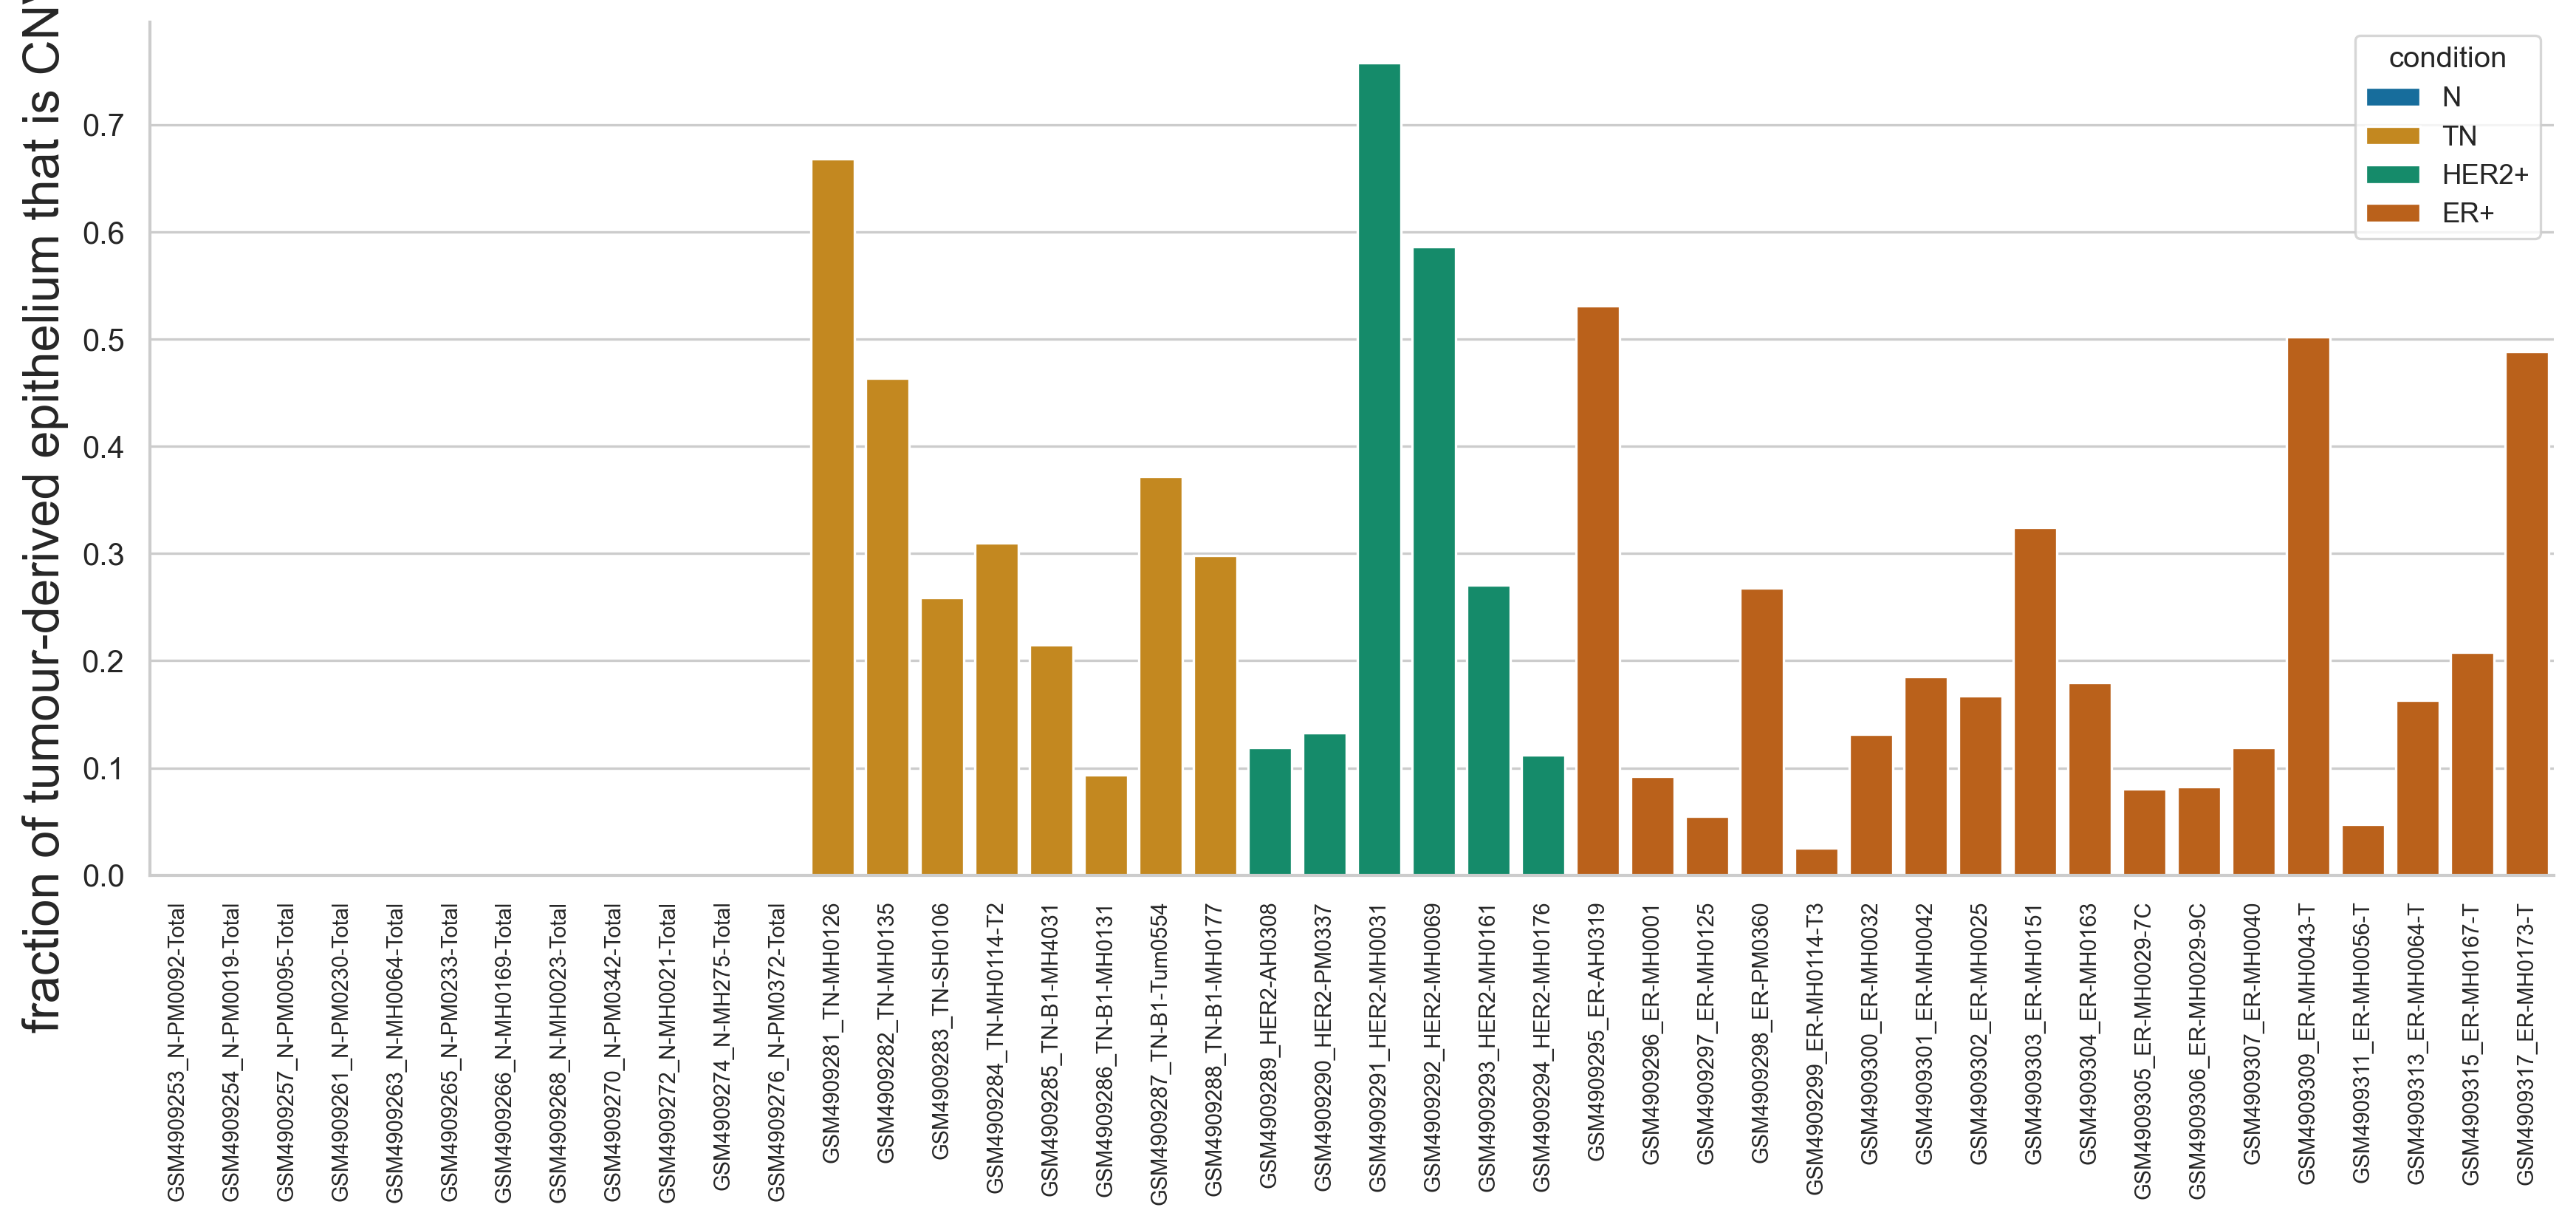

In [86]:
plot_data = sample_population_summary[
    sample_population_summary["condition"].ne("N")
].copy()

fig, ax = plt.subplots(figsize=(14, 5))


sns.barplot(
    data=plot_data,
    x="sample",
    y="tumour_derived_cnv_high_fraction",
    hue="condition",
    dodge=False,
    ax=ax,
)

ax.set_xlabel("")
ax.set_ylabel("fraction of tumour-derived epithelium that is CNV-high")
ax.tick_params(axis="x", rotation=90, labelsize=7)


sns.despine()

plt.savefig(
    fig_dir / "tumour_derived_cnv_high_fraction_by_sample.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [87]:
# transfer the inferCNV results onto the master object
assert epi.obs_names.equals(cnv_adata.obs_names)


In [88]:
transfer_columns = [
    "cnv_score", "cnv_signal", "tumour_derived", "cnv_high",
    "tumour_derived_cnv_high", "g1_cell", "tumour_derived_cnv_high_g1",
    "specimen_origin", "source_tumour_cluster",
    "source_tumour_cluster_eligible", "source_tumour_cluster_call",
]

for column in transfer_columns:
    epi.obs[column] = cnv_adata.obs[column].reindex(epi.obs_names)


In [89]:
boolean_columns = [
    "tumour_derived", "cnv_high", "tumour_derived_cnv_high", "g1_cell",
    "tumour_derived_cnv_high_g1", "source_tumour_cluster",
    "source_tumour_cluster_eligible",
]
for column in boolean_columns:
    epi.obs[column] = epi.obs[column].astype(bool)

epi.obs["specimen_origin"] = pd.Categorical(
    epi.obs["specimen_origin"], categories=origin_order
)
epi.obs["source_tumour_cluster_call"] = pd.Categorical(
    epi.obs["source_tumour_cluster_call"], categories=source_call_order
)


In [90]:
epi.uns["epithelial_population_definitions"] = {
    "primary_population": "specimen origin",
    "tumour_derived": "epithelial cells from ER+, HER2+ or TN specimens",
    "normal_tissue": "epithelial cells from normal specimens",
    "tumour_derived_cnv_high": "tumour-derived and CNV burden above normal q95",
    "tumour_derived_cnv_high_limitation": (
        "conservative CNV-enriched subgroup; does not classify all tumour-derived cells"
    ),
    "cnv_method": "infercnvpy",
    "cnv_reference": "normal epithelial cells; leave-one-sample-out for normal samples",
    "gene_annotation": "GENCODE v50 joined by Ensembl gene ID",
    "expression_layer": "log-normalised expression",
    "window_size": 100,
    "step": 10,
    "dynamic_threshold": float(infercnv_dynamic_threshold),
    "cnv_score": "chromosome-level RMS burden weighted by window count",
    "cnv_high_normal_quantile": float(cnv_high_quantile),
    "cnv_high_threshold": cnv_high_threshold,
    "cnv_high_threshold_g1_reference": cnv_high_threshold_g1,
    "source_cluster_file": source_tumour_file.name,
    "source_cluster_rows": int(len(source_tumour)),
    "cnv_score_vs_total_counts_r": float(r),
}


In [91]:
pd.DataFrame({
    "tumour_derived": [int(epi.obs["tumour_derived"].sum())],
    "normal_tissue": [int((~epi.obs["tumour_derived"]).sum())],
    "cnv_high_all_epithelium": [int(epi.obs["cnv_high"].sum())],
    "tumour_derived_cnv_high": [int(epi.obs["tumour_derived_cnv_high"].sum())],
    "tumour_derived_cnv_high_g1": [int(epi.obs["tumour_derived_cnv_high_g1"].sum())],
    "source_tumour_clusters": [int(epi.obs["source_tumour_cluster"].sum())],
})


,tumour_derived,normal_tissue,cnv_high_all_epithelium,tumour_derived_cnv_high,tumour_derived_cnv_high_g1,source_tumour_clusters
0,103429,25682,23612,22327,11019,70719


In [92]:
cnv_adata.obsm["X_cnv"] = x_cnv_full


In [93]:
cnv_adata.write_h5ad(save_dir / "epithelial_infercnv.h5ad", compression="gzip")


In [94]:
del cnv_adata, reference, x_cnv_full
gc.collect()


408

## scVI integration

In [95]:
epi_scvi = epi[:, epi.var["highly_variable"]].copy()


In [96]:
assert epi_scvi.n_obs == epi.n_obs
assert epi_scvi.n_vars == n_hvg_deviance


In [97]:
epi_scvi.shape


(129111, 4000)

In [98]:
# sample (library) identity is the batch covariate
scvi.model.SCVI.setup_anndata(epi_scvi, layer="counts", batch_key="sample")


In [99]:
model = scvi.model.SCVI(
    epi_scvi,
    n_latent=n_latent,
    n_layers=n_layers,
    gene_likelihood=gene_likelihood,
)


In [100]:
# free the large intermediates; nothing below uses them
del epi_scvi
gc.collect()


8205

In [101]:
model


SCVI model with the following parameters: 
n_hidden: 128, n_latent: 20, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [102]:
# min_delta of 1.0 nat on the ELBO stops training once the remaining gain is small relative to the reconstruction term; it sets the epoch count reported
model.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and tr

Epoch 195/400:  49%|████▉     | 195/400 [35:19<37:08, 10.87s/it, v_num=1, train_loss=2.77e+3]
Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2808.212. Signaling Trainer to stop.


In [103]:
n_epochs = model.history["elbo_train"].shape[0]


In [104]:
n_epochs


195

In [105]:
model.save(str(model_dir), overwrite=True)
model.history["elbo_train"].to_csv(df_dir / "scvi_epithelial_history.csv")


In [106]:
latent = model.get_latent_representation()


In [107]:
assert latent.shape == (epi.n_obs, 20)
assert np.isfinite(latent).all()


In [108]:
epi.obsm["X_scVI"] = latent


In [109]:
latent.shape


(129111, 20)

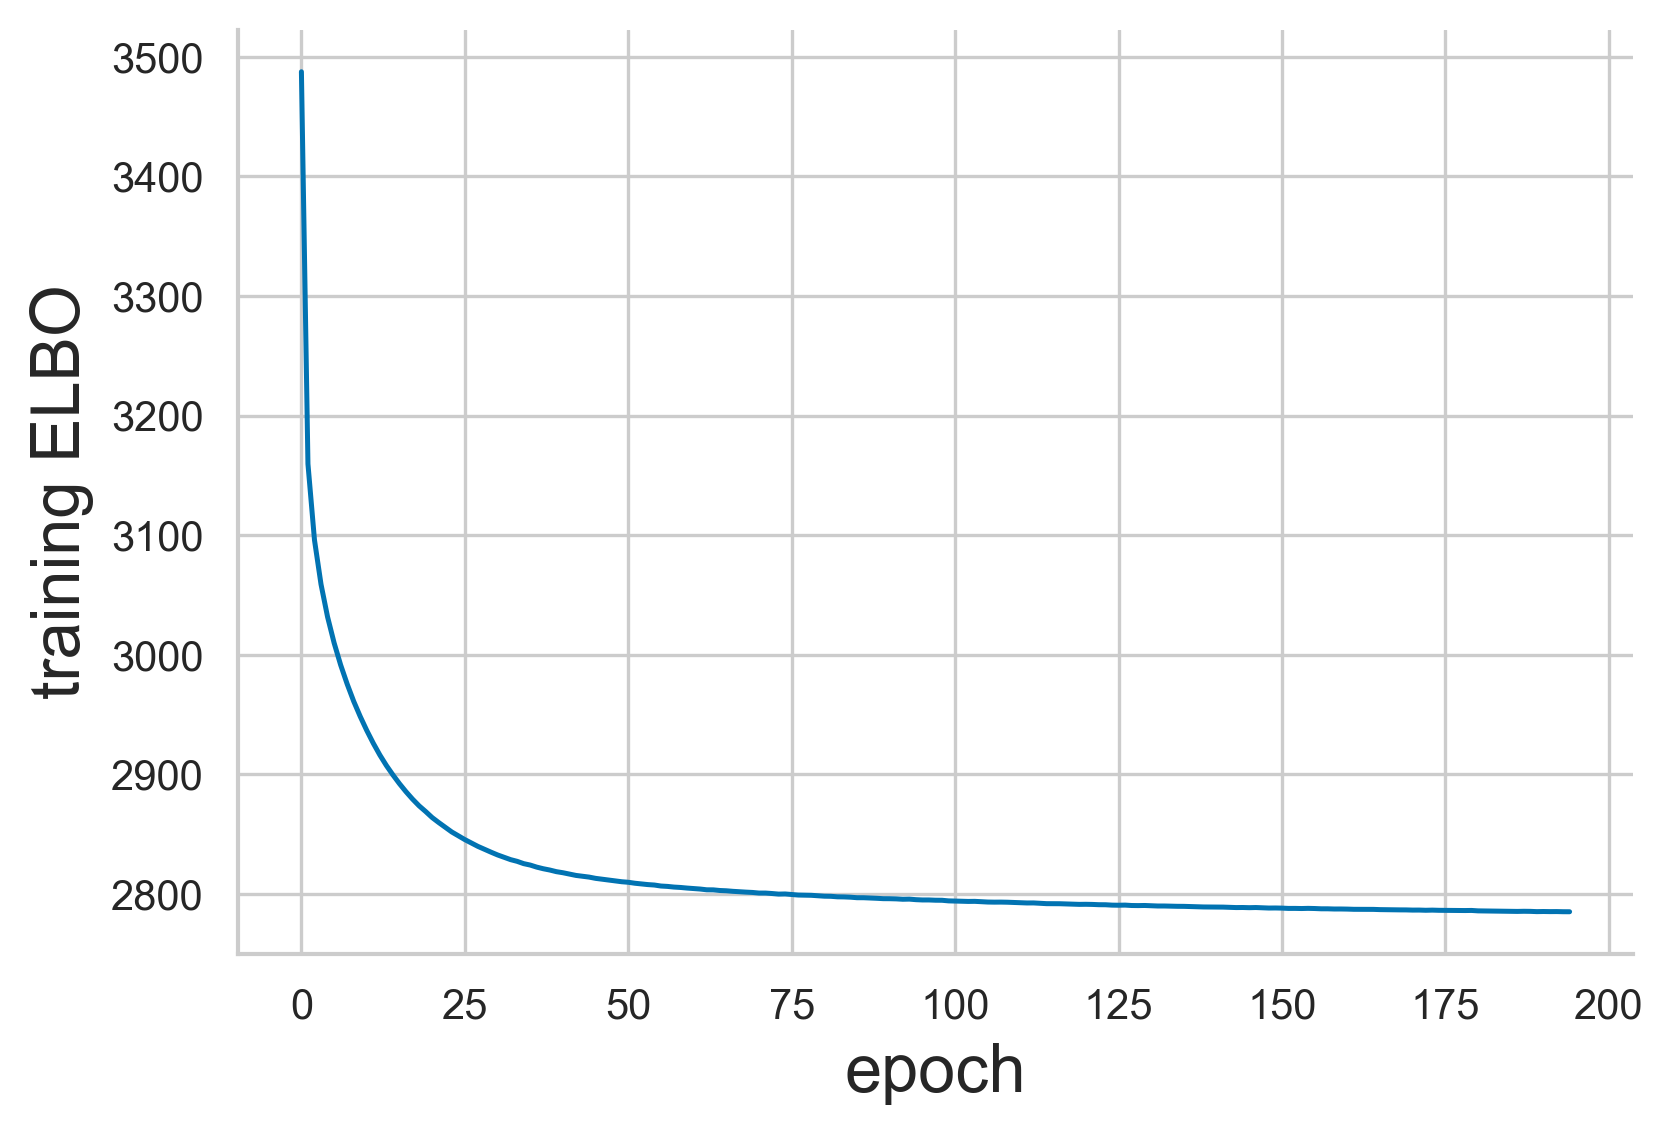

In [110]:
fig, ax = plt.subplots(figsize=(6, 4))

training_history = pd.read_csv(df_dir / "scvi_epithelial_history.csv", index_col=0)
training_history.plot(ax=ax, legend=False)

ax.set_xlabel("epoch")
ax.set_ylabel("training ELBO")
sns.despine()

plt.savefig(fig_dir / "scvi_epithelial_elbo.png", dpi=300, bbox_inches="tight")
plt.show()


In [111]:
# =====================  CHECKPOINT: SAVE  =====================
import json, pickle, platform, hashlib, os, gc
from pathlib import Path
import numpy as np, pandas as pd, scipy.sparse as sp
import scanpy as sc, anndata as ad, scvi
import importlib.metadata as md

ckpt_dir = save_dir / "checkpoints" / "epithelial_post_scvi"
ckpt_dir.mkdir(parents=True, exist_ok=True)
ckpt_h5ad = ckpt_dir / "epi_checkpoint.h5ad"

# an older manifest must not vouch for a half-written new checkpoint
(ckpt_dir / "manifest.json").unlink(missing_ok=True)

# ---- 1 | pre-flight: every label/embedding that downstream cells use must exist
need_obs = [
    "sample", "sample_short", "condition", "phase", "cl_annotation", "total_counts",
    "cnv_score", "cnv_signal", "tumour_derived", "cnv_high", "tumour_derived_cnv_high",
    "g1_cell", "tumour_derived_cnv_high_g1", "specimen_origin",
    "source_tumour_cluster", "source_tumour_cluster_eligible", "source_tumour_cluster_call",
]
need_var = ["highly_variable", "highly_variable_deviance",
            "highly_variable_protected", "binomial_deviance"]
need_obsm = ["X_scVI"]
need_layers = ["counts", "lognorm", "log1p"]

problems = (
        [f"obs missing: {c}" for c in need_obs if c not in epi.obs.columns]
        + [f"var missing: {c}" for c in need_var if c not in epi.var.columns]
        + [f"obsm missing: {k}" for k in need_obsm if k not in epi.obsm]
        + [f"layer missing: {k}" for k in need_layers if k not in epi.layers]
)
assert not problems, problems
assert epi.obs_names.is_unique and epi.var_names.is_unique
assert (epi.n_obs, epi.n_vars) == (n_cells_start, n_genes_start)
assert epi.obsm["X_scVI"].shape == (epi.n_obs, n_latent)
assert np.isfinite(epi.obsm["X_scVI"]).all()

must_be_complete = ["sample", "condition", "specimen_origin",
                    "source_tumour_cluster_call", "cnv_score", "cnv_signal"]
assert not epi.obs[must_be_complete].isna().any().any(), \
    epi.obs[must_be_complete].isna().sum()

# ---- 2 | make in-memory dtypes identical to what h5ad stores
epi.strings_to_categoricals()
for name in list(epi.layers.keys()):
    if not sp.issparse(epi.layers[name]):
        epi.layers[name] = sp.csr_matrix(epi.layers[name])
if not sp.issparse(epi.X):
    epi.X = sp.csr_matrix(epi.X)

# ---- 3 | main file (written to .tmp first, then swapped in)
tmp = ckpt_h5ad.with_suffix(".h5ad.tmp")
epi.write_h5ad(tmp, compression="gzip")
os.replace(tmp, ckpt_h5ad)

# ---- 4 | independent backups of labels, var and embeddings
epi.obs.to_pickle(ckpt_dir / "obs.pkl")          # exact dtypes, categories, order
epi.var.to_pickle(ckpt_dir / "var.pkl")
epi.obs.to_csv(ckpt_dir / "obs.csv.gz")          # human-readable copy
np.savez_compressed(ckpt_dir / "obsm.npz",
                    **{k: np.asarray(v) for k, v in epi.obsm.items()})

# ---- 5 | python state needed by the cells below
state_names = [
    # parameters
    "target_genes", "random_seed", "n_hvg_primary", "cnv_high_quantile",
    "infercnv_dynamic_threshold", "cnv_quantiles", "n_latent", "n_layers",
    "gene_likelihood", "n_neighbors", "primary_resolution", "leiden_resolutions",
    # master shapes / counts
    "n_cells_loaded", "n_genes_loaded", "n_genes_removed", "n_cells_start",
    "n_genes_start", "baseline_positive", "shape_summary",
    # HVG
    "n_hvg_deviance", "n_hvg_protected", "n_protected_added", "deviant_genes",
    "protected_present", "meta_programme_genes", "deviance", "hvg_summary",
    # inferCNV / population calls
    "cnv_high_threshold", "cnv_high_threshold_g1", "normal_scores", "normal_g1_scores",
    "r", "origin_order", "source_call_order", "source_tumour", "transfer_exclusions",
    "threshold_sensitivity", "cycle_cnv_summary", "sample_population_summary",
    "population_counts", "cnv_samples", "actual_source_tumour_sha256",
    # scVI
    "n_epochs", "training_history",
]
state, state_missing, state_unpicklable = {}, [], []
for k in state_names:
    if k not in globals():
        state_missing.append(k); continue
    try:
        pickle.dumps(globals()[k]); state[k] = globals()[k]
    except Exception:
        state_unpicklable.append(k)
with open(ckpt_dir / "state.pkl", "wb") as fh:
    pickle.dump(state, fh, protocol=5)

# ---- 6 | trained scVI model (weights + registry; data comes from epi on load)
model_saved = False
if "model" in globals():
    model.save(str(ckpt_dir / "scvi_model"), overwrite=True, save_anndata=False)
    model_saved = True

# ---- 7 | read everything back and compare
def same_matrix(a, b):
    if sp.issparse(a) or sp.issparse(b):
        return a.shape == b.shape and (sp.csr_matrix(a) != sp.csr_matrix(b)).nnz == 0
    return np.array_equal(a, b)

chk = sc.read_h5ad(ckpt_h5ad)
assert chk.shape == epi.shape
assert chk.obs_names.equals(epi.obs_names) and chk.var_names.equals(epi.var_names)
pd.testing.assert_frame_equal(chk.obs, epi.obs, check_exact=True, check_categorical=True)
pd.testing.assert_frame_equal(chk.var, epi.var, check_exact=True, check_categorical=True)
assert set(chk.obsm) == set(epi.obsm)
for k in epi.obsm:
    assert np.array_equal(np.asarray(chk.obsm[k]), np.asarray(epi.obsm[k]), equal_nan=True), k
assert set(chk.layers) == set(epi.layers)
for k in epi.layers:
    assert same_matrix(chk.layers[k], epi.layers[k]), k
assert same_matrix(chk.X, epi.X)
assert set(chk.obsp) == set(epi.obsp)
for k in epi.obsp:
    assert same_matrix(chk.obsp[k], epi.obsp[k]), k
assert set(chk.uns) == set(epi.uns), set(chk.uns) ^ set(epi.uns)
del chk; gc.collect()

# ---- 8 | manifest (written last; the loader refuses a checkpoint without it)
def sha256(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while block := fh.read(chunk):
            h.update(block)
    return h.hexdigest()

def ver(pkg):
    try: return md.version(pkg)
    except Exception: return "n/a"

manifest = {
    "complete": True,
    "n_obs": int(epi.n_obs), "n_vars": int(epi.n_vars),
    "obs_columns": {c: str(t) for c, t in epi.obs.dtypes.items()},
    "obsm": {k: list(np.asarray(v).shape) for k, v in epi.obsm.items()},
    "layers": list(epi.layers), "uns_keys": list(epi.uns),
    "state_missing": state_missing, "state_unpicklable": state_unpicklable,
    "model_saved": model_saved,
    "infercnv_file_on_disk": (save_dir / "epithelial_infercnv.h5ad").exists(),
    "project": str(project),
    "sha256_h5ad": sha256(ckpt_h5ad),
    "python": platform.python_version(),
    "versions": {p: ver(p) for p in
                 ["scanpy", "anndata", "scvi-tools", "torch", "pandas", "numpy", "scipy", "infercnvpy"]},
}
(ckpt_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))

print(f"checkpoint OK -> {ckpt_dir}")
print(f"{epi.n_obs:,} cells x {epi.n_vars:,} genes | {epi.obs.shape[1]} obs columns | "
      f"obsm: {list(epi.obsm)} | model saved: {model_saved}")
print("state not defined at this point (ignored):", state_missing)
if state_unpicklable:
    print("WARNING, not picklable:", state_unpicklable)

checkpoint OK -> /Volumes/TOSHIBA EXT/IdeaProjects/Nowotny/Adata_Saves/checkpoints/epithelial_post_scvi
129,111 cells x 27,356 genes | 39 obs columns | obsm: ['X_pca', 'X_scVI', 'X_umap', 'X_umap_atlas'] | model saved: True
state not defined at this point (ignored): ['transfer_exclusions']


## Checkpoint here

## Neighbours, UMAP and Leiden clustering

In [1]:
# =====================  CHECKPOINT: LOAD (fresh kernel)  =====================
import gc, os, re, sys, json, pickle, logging
import importlib.metadata as md
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

import scanpy as sc
import anndata as ad
import infercnvpy as cnv
import scvi

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

import rpy2.robjects as ro
import rpy2.rinterface_lib.callbacks as rcb

LOAD_MODEL = True      # cell 190 does `del model`, so keep True unless you remove that line
VERIFY_HASH = False    # True re-hashes the h5ad (slow, big file)

# ---- settings from the setup section
np.random.seed(0)
scvi.settings.seed = 0
scvi.settings.num_workers = 4
sc.settings.verbosity = 2
rcb.logger.setLevel(logging.ERROR)

sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({
    "font.size": 20, "axes.titlesize": 20, "axes.labelsize": 16,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "figure.dpi": 300,
})

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Error importing in API mode: ImportError("dlopen(/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: @rpath/R/lib/libR.dylib\n  Referenced from: <CBEF4F67-1D94-3EA0-88C4-F34EBE0600C2> /Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/../../R/lib/libR.dylib' (no such file), '/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/si

In [3]:
# ---- helpers and paths (as in the setup section)
def find_project(start=None):
    here = Path(start or Path.cwd()).resolve()
    for parent in [here, *here.parents]:
        if (parent / "Data").is_dir() and (parent / "metadata").is_dir():
            return parent
    raise FileNotFoundError("Set CAP_PROJECT to the project data directory")

def find_publication():
    here = Path.cwd().resolve()
    for parent in [here, *here.parents]:
        for candidate in (parent, parent / "publication_notebooks"):
            if (candidate / "scripts" / "publication_figure_state.py").is_file():
                if (candidate / "data" / "cancer_meta_programme_signatures.xlsx").is_file():
                    return candidate
    raise FileNotFoundError("Run from the publication_notebooks directory")

def rel(path):
    return Path(path).relative_to(project)

def sample_code(sample):
    sample_name = str(sample).split("_", 1)[-1]
    matches = re.findall(r"(?<!\d)(\d{4})(?!\d)", sample_name)
    return matches[-1] if matches else ""

project = Path(os.environ.get("CAP_PROJECT") or find_project()).expanduser().resolve()
data_dir = project / "Data"
fig_dir = project / "Figures"
df_dir = project / "Dataframe_Saves"
save_dir = project / "Adata_Saves"
model_dir = project / "scvi_epithelial_model"
notebook_dir = find_publication()
sc.settings.figdir = fig_dir

meta_programme_file = notebook_dir / "data" / "cancer_meta_programme_signatures.xlsx"
gencode_file = data_dir / "gencode.v50.annotation.gtf.gz"
source_tumour_file = notebook_dir / "data" / "source_tumour_cluster_barcodes.csv.gz"

# ---- locate and validate the checkpoint
ckpt_dir = save_dir / "checkpoints" / "epithelial_post_scvi"
manifest_path = ckpt_dir / "manifest.json"
assert manifest_path.exists(), "no complete checkpoint found (manifest.json missing)"
manifest = json.loads(manifest_path.read_text())
assert manifest["complete"]

for pkg, old in manifest["versions"].items():
    try: now = md.version(pkg)
    except Exception: now = "n/a"
    if now != old:
        print(f"WARNING version differs: {pkg} saved={old} now={now}")

ckpt_h5ad = ckpt_dir / "epi_checkpoint.h5ad"
if VERIFY_HASH:
    import hashlib
    h = hashlib.sha256()
    with open(ckpt_h5ad, "rb") as fh:
        while block := fh.read(1 << 24):
            h.update(block)
    assert h.hexdigest() == manifest["sha256_h5ad"], "h5ad changed since it was saved"

# ---- the object
epi = sc.read_h5ad(ckpt_h5ad)
assert (epi.n_obs, epi.n_vars) == (manifest["n_obs"], manifest["n_vars"])

# labels, var and embeddings must match the independent backups exactly
pd.testing.assert_frame_equal(epi.obs, pd.read_pickle(ckpt_dir / "obs.pkl"),
                              check_exact=True, check_categorical=True)
pd.testing.assert_frame_equal(epi.var, pd.read_pickle(ckpt_dir / "var.pkl"),
                              check_exact=True, check_categorical=True)
with np.load(ckpt_dir / "obsm.npz") as z:
    assert set(z.files) == set(epi.obsm), set(z.files) ^ set(epi.obsm)
    for k in z.files:
        assert np.array_equal(z[k], np.asarray(epi.obsm[k]), equal_nan=True), k
assert {c: str(t) for c, t in epi.obs.dtypes.items()} == manifest["obs_columns"]

# ---- python state
with open(ckpt_dir / "state.pkl", "rb") as fh:
    state = pickle.load(fh)
assert "epi" not in state
globals().update(state)
if str(project) != manifest["project"]:
    print("WARNING: project path differs from the one used at save time")

# ---- scVI model (weights restored against the same HVG matrix)
if LOAD_MODEL and manifest["model_saved"]:
    epi_scvi = epi[:, epi.var["highly_variable"]].copy()
    assert epi_scvi.n_vars == n_hvg_deviance
    model = scvi.model.SCVI.load(str(ckpt_dir / "scvi_model"), adata=epi_scvi)
    del epi_scvi
    gc.collect()

# ---- sanity checks
assert epi.n_obs == n_cells_start and epi.n_vars == n_genes_start
assert epi.obsm["X_scVI"].shape == (epi.n_obs, n_latent)
assert np.isfinite(epi.obsm["X_scVI"]).all()
now_positive = {
    g: int((np.asarray(epi[:, g].layers["counts"].todense()).ravel() > 0).sum())
    for g in target_genes
}
assert now_positive == baseline_positive, (now_positive, baseline_positive)
print(f"restored {epi.n_obs:,} cells x {epi.n_vars:,} genes | "
      f"X_scVI {epi.obsm['X_scVI'].shape} | model: {'model' in globals()}")
print("not available (defined later or after this point):", manifest["state_missing"])

INFO     File /Volumes/TOSHIBA                                                                                     
         EXT/IdeaProjects/Nowotny/Adata_Saves/checkpoints/epithelial_post_scvi/scvi_model/model.pt already         
         downloaded                                                                                                


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scvi/model/base/_base_model.py:862: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  _, _, device = parse_device_args(


restored 129,111 cells x 27,356 genes | X_scVI (129111, 20) | model: True
not available (defined later or after this point): ['transfer_exclusions']


In [4]:
sc.pp.neighbors(epi, use_rep="X_scVI", n_neighbors=n_neighbors, random_state=random_seed)
sc.tl.umap(epi, random_state=random_seed)


computing neighbors
    finished (0:00:42)
computing UMAP
    finished (0:01:55)


In [5]:
from sklearn.metrics import adjusted_rand_score


In [6]:
leiden_summary = []


In [7]:
for resolution in leiden_resolutions:
    key = f"leiden_r{resolution:g}"
    sc.tl.leiden(
        epi,
        resolution=resolution,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
        directed=False,
        random_state=random_seed,
    )
    leiden_summary.append({"resolution": resolution, "n_clusters": epi.obs[key].nunique()})


running Leiden clustering
    finished (0:00:22)
running Leiden clustering
    finished (0:00:24)
running Leiden clustering
    finished (0:00:22)
running Leiden clustering
    finished (0:00:09)


In [8]:
display(pd.DataFrame(leiden_summary))


,resolution,n_clusters
0,0.5,18
1,1.0,27
2,1.2,28
3,1.5,30


In [9]:
primary_key = f"leiden_r{primary_resolution:g}"
resolution_stability = pd.DataFrame({
    "resolution": leiden_resolutions,
    "ari_vs_primary": [
        adjusted_rand_score(epi.obs[primary_key], epi.obs[f"leiden_r{resolution:g}"])
        for resolution in leiden_resolutions
    ],
})
display(resolution_stability.round(3))


,resolution,ari_vs_primary
0,0.5,1.000
1,1.0,0.486
2,1.2,0.453
3,1.5,0.409


In [10]:
epi.obs["epi_leiden"] = epi.obs[primary_key].copy()


In [11]:
epi.obs["epi_leiden"].value_counts().sort_index()


epi_leiden
0     16005
1      4416
2      3631
3     16532
4      4731
5     40005
6       968
7      8482
8      7685
9     11610
10       52
11     8937
12     2395
13     1024
14     2122
15      242
16       90
17      184
Name: count, dtype: int64

## Integration diagnostics

In [12]:
from sklearn.metrics import silhouette_score


In [13]:
rng = np.random.default_rng(0)

n_eval = min(20000, epi.n_obs)
eval_idx = rng.choice(epi.n_obs, size=n_eval, replace=False)

z_eval = epi.obsm["X_scVI"][eval_idx]
obs_eval = epi.obs.iloc[eval_idx]

bio_asw = silhouette_score(z_eval, obs_eval["cl_annotation"], metric="euclidean")
batch_asw = silhouette_score(z_eval, obs_eval["sample"], metric="euclidean")

print(f"annotation silhouette: {bio_asw:.3f}")


annotation silhouette: 0.034


In [14]:
print(f"sample silhouette:     {batch_asw:.3f}")


sample silhouette:     -0.072


In [15]:
pd.DataFrame({
    "metric": ["annotation_silhouette", "sample_silhouette"],
    "value": [bio_asw, batch_asw],
}).to_csv(df_dir / "scvi_epithelial_integration_metrics.csv", index=False)


In [16]:
cluster_composition = pd.crosstab(
    epi.obs["epi_leiden"], epi.obs["sample"], normalize="index"
)
cluster_composition["top_sample_fraction"] = cluster_composition.max(axis=1)
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")
display(cluster_composition.sort_values("top_sample_fraction", ascending=False).round(3))


sample,GSM4909253_N-PM0092-Total,GSM4909254_N-PM0019-Total,GSM4909257_N-PM0095-Total,GSM4909261_N-PM0230-Total,GSM4909263_N-MH0064-Total,GSM4909265_N-PM0233-Total,GSM4909266_N-MH0169-Total,GSM4909268_N-MH0023-Total,GSM4909270_N-PM0342-Total,GSM4909272_N-MH0021-Total,...,GSM4909304_ER-MH0163,GSM4909305_ER-MH0029-7C,GSM4909306_ER-MH0029-9C,GSM4909307_ER-MH0040,GSM4909309_ER-MH0043-T,GSM4909311_ER-MH0056-T,GSM4909313_ER-MH0064-T,GSM4909315_ER-MH0167-T,GSM4909317_ER-MH0173-T,top_sample_fraction
epi_leiden,,,,,,,,,,,,,,,,,,,,,
17,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
16,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
15,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.004,0.000,0.004,0.000,0.000,0.000,0.000,0.012,0.959
10,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.019,0.904,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.904
6,0.000,0.000,0.006,0.000,0.000,0.002,0.036,0.002,0.000,0.000,...,0.032,0.001,0.003,0.000,0.003,0.001,0.000,0.011,0.002,0.709
1,0.002,0.001,0.001,0.000,0.000,0.001,0.000,0.000,0.000,0.001,...,0.003,0.001,0.001,0.004,0.000,0.004,0.001,0.001,0.000,0.620
13,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.000,0.000,...,0.004,0.000,0.004,0.000,0.000,0.000,0.003,0.000,0.001,0.515
14,0.015,0.054,0.002,0.004,0.000,0.049,0.002,0.002,0.002,0.000,...,0.001,0.007,0.005,0.001,0.066,0.003,0.022,0.000,0.089,0.402
7,0.002,0.002,0.000,0.001,0.000,0.004,0.001,0.001,0.002,0.001,...,0.043,0.008,0.014,0.015,0.022,0.011,0.028,0.004,0.006,0.391


In [17]:
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")


In [18]:
cluster_population = (
    epi.obs
    .groupby("epi_leiden", observed=True)
    .agg(
        n_cells=("tumour_derived", "size"),
        n_tumour_derived=("tumour_derived", "sum"),
        n_tumour_derived_cnv_high=("tumour_derived_cnv_high", "sum"),
        n_tumour_derived_cnv_high_g1=("tumour_derived_cnv_high_g1", "sum"),
        median_cnv=("cnv_score", "median"),
    )
)


In [19]:
cluster_population["tumour_derived_fraction"] = (
    cluster_population["n_tumour_derived"] / cluster_population["n_cells"]
)
cluster_population["tumour_derived_cnv_high_fraction"] = (
    cluster_population["n_tumour_derived_cnv_high"] / cluster_population["n_cells"]
)


In [20]:
cluster_population.sort_values(
    "tumour_derived_cnv_high_fraction", ascending=False
).round(3)


,n_cells,n_tumour_derived,n_tumour_derived_cnv_high,n_tumour_derived_cnv_high_g1,median_cnv,tumour_derived_fraction,tumour_derived_cnv_high_fraction
epi_leiden,,,,,,,
10,52,52,38,27,0.044,1.000,0.731
3,16532,16287,7539,296,0.040,0.985,0.456
16,90,90,35,22,0.040,1.000,0.389
5,40005,39751,7942,6076,0.036,0.994,0.199
12,2395,1951,373,247,0.035,0.815,0.156
13,1024,1023,156,115,0.035,0.999,0.152
7,8482,8350,1260,836,0.035,0.984,0.149
0,16005,6591,2244,1422,0.026,0.412,0.140
9,11610,5910,1467,1218,0.033,0.509,0.126


In [21]:
cluster_population.to_csv(
    df_dir / "scvi_epithelial_cluster_population_composition.csv"
)


In [22]:
# canonical epithelial markers, to confirm the clusters are epithelial
marker_genes = [
    g for g in ["EPCAM", "KRT8", "KRT18", "KRT19", "KRT7", "KRT5", "KRT14", "KRT17", "MUC1"]
    if g in epi.var_names
]


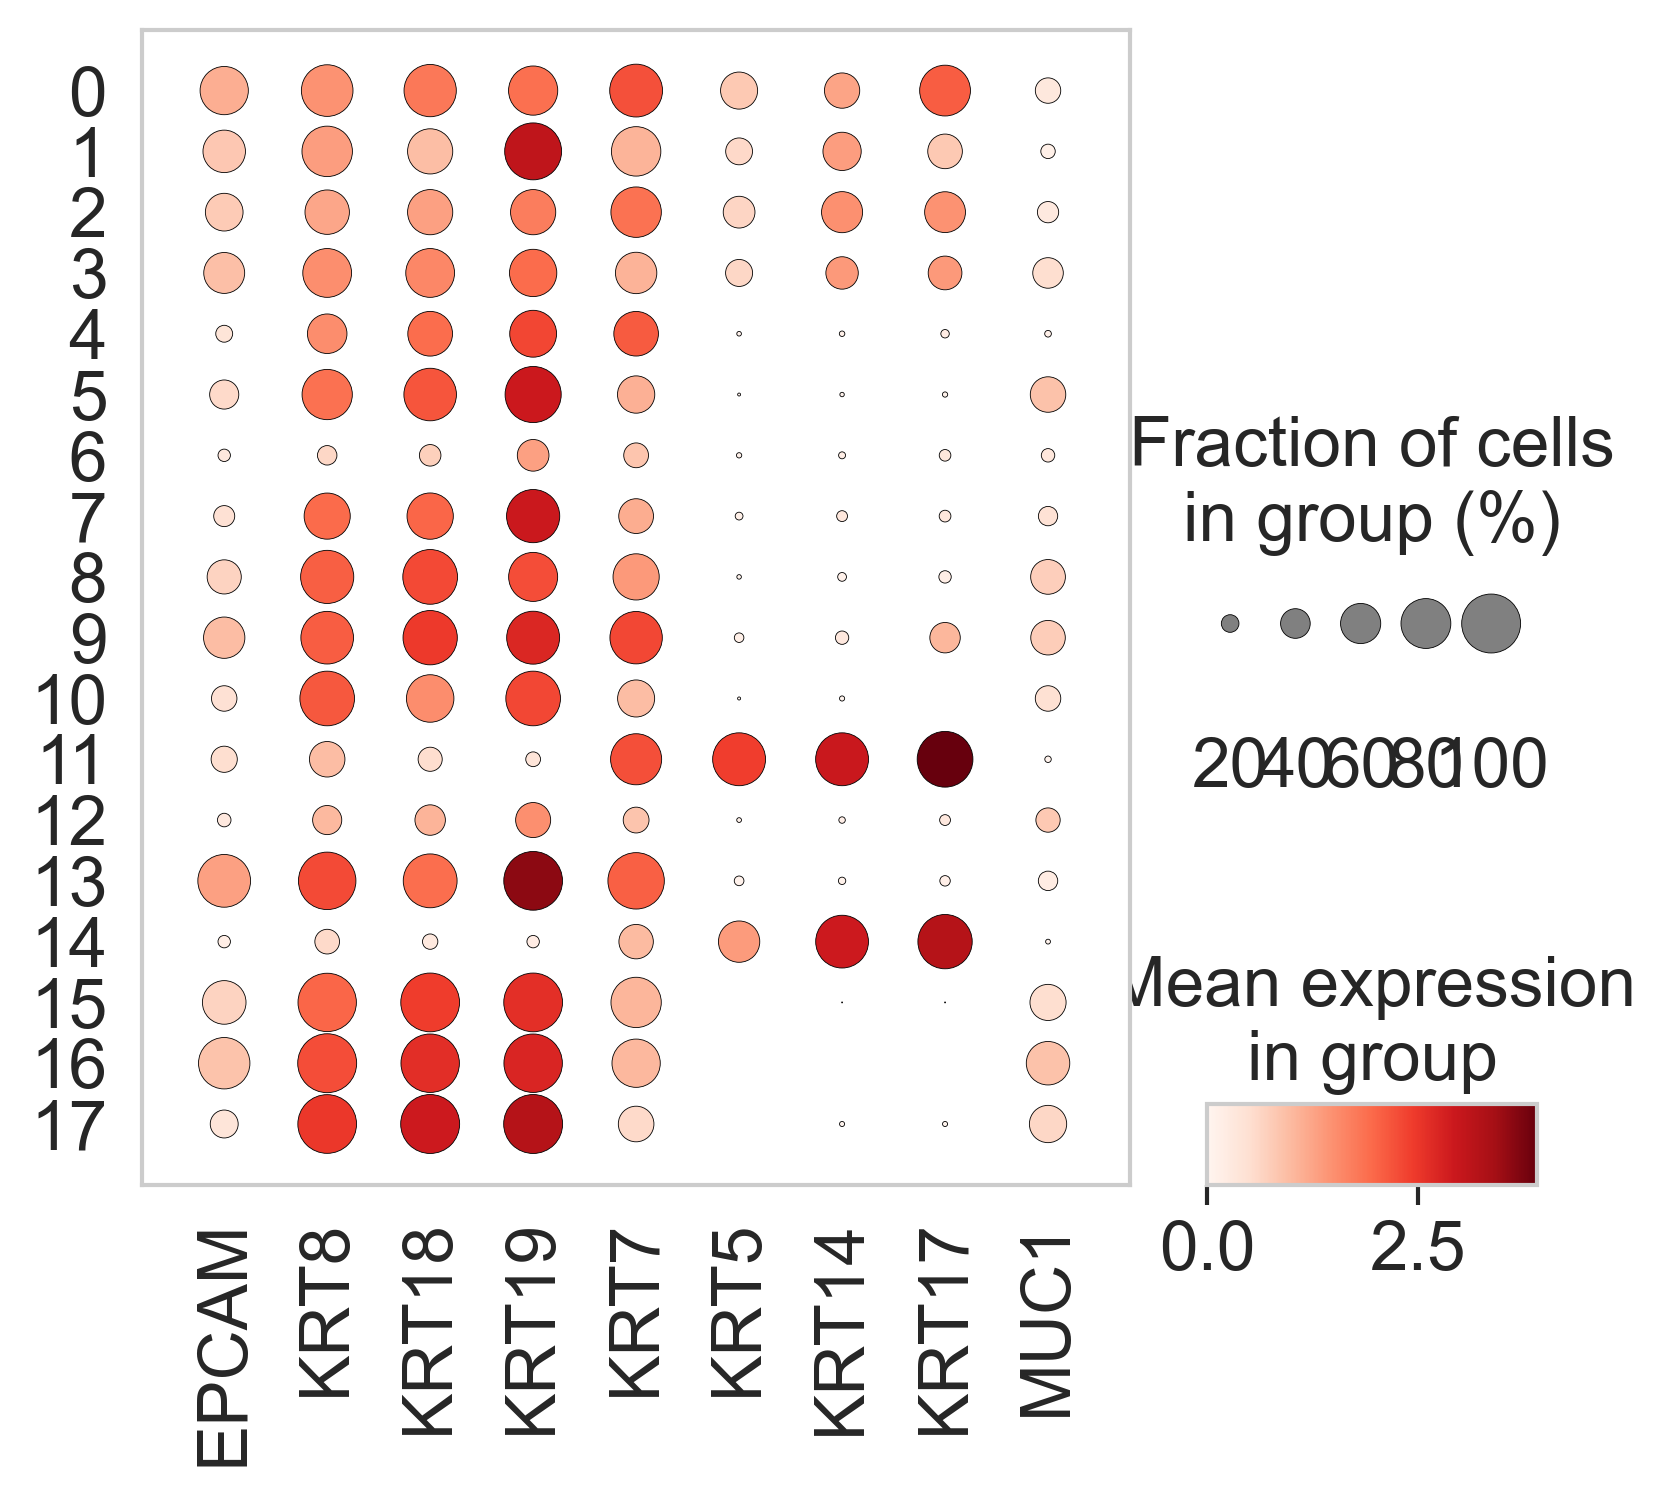

In [23]:
sc.pl.dotplot(
    epi,
    var_names=marker_genes,
    groupby="epi_leiden",
    layer="lognorm",
    use_raw=False,
    figsize=(6, 5),
    show=False,
)

plt.savefig(fig_dir / "epithelial_cluster_markers_dotplot.png", dpi=300, bbox_inches="tight")
plt.show()


## Figure 1a and related UMAPs

In [24]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}


In [25]:
condition_order = ["TN", "HER2+", "ER+", "N"]


In [26]:
epi.obs["condition"] = pd.Categorical(
    epi.obs["condition"].astype(str), categories=condition_order, ordered=True
)


In [27]:
# set the colours on the object, so plotting a subset does not have to write them
epi.uns["condition_colors"] = [condition_palette[c] for c in condition_order]


In [28]:
epi.obs["cl_annotation"] = epi.obs["cl_annotation"].astype("category")


In [29]:
epi.obs["sample_short"] = (
    epi.obs["sample_short"].astype("category").cat.remove_unused_categories()
)


In [30]:
# draw N first so that the tumour conditions are not hidden underneath it
draw_order = ["N", "TN", "HER2+", "ER+"]
rank = {condition: i for i, condition in enumerate(draw_order)}

plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index


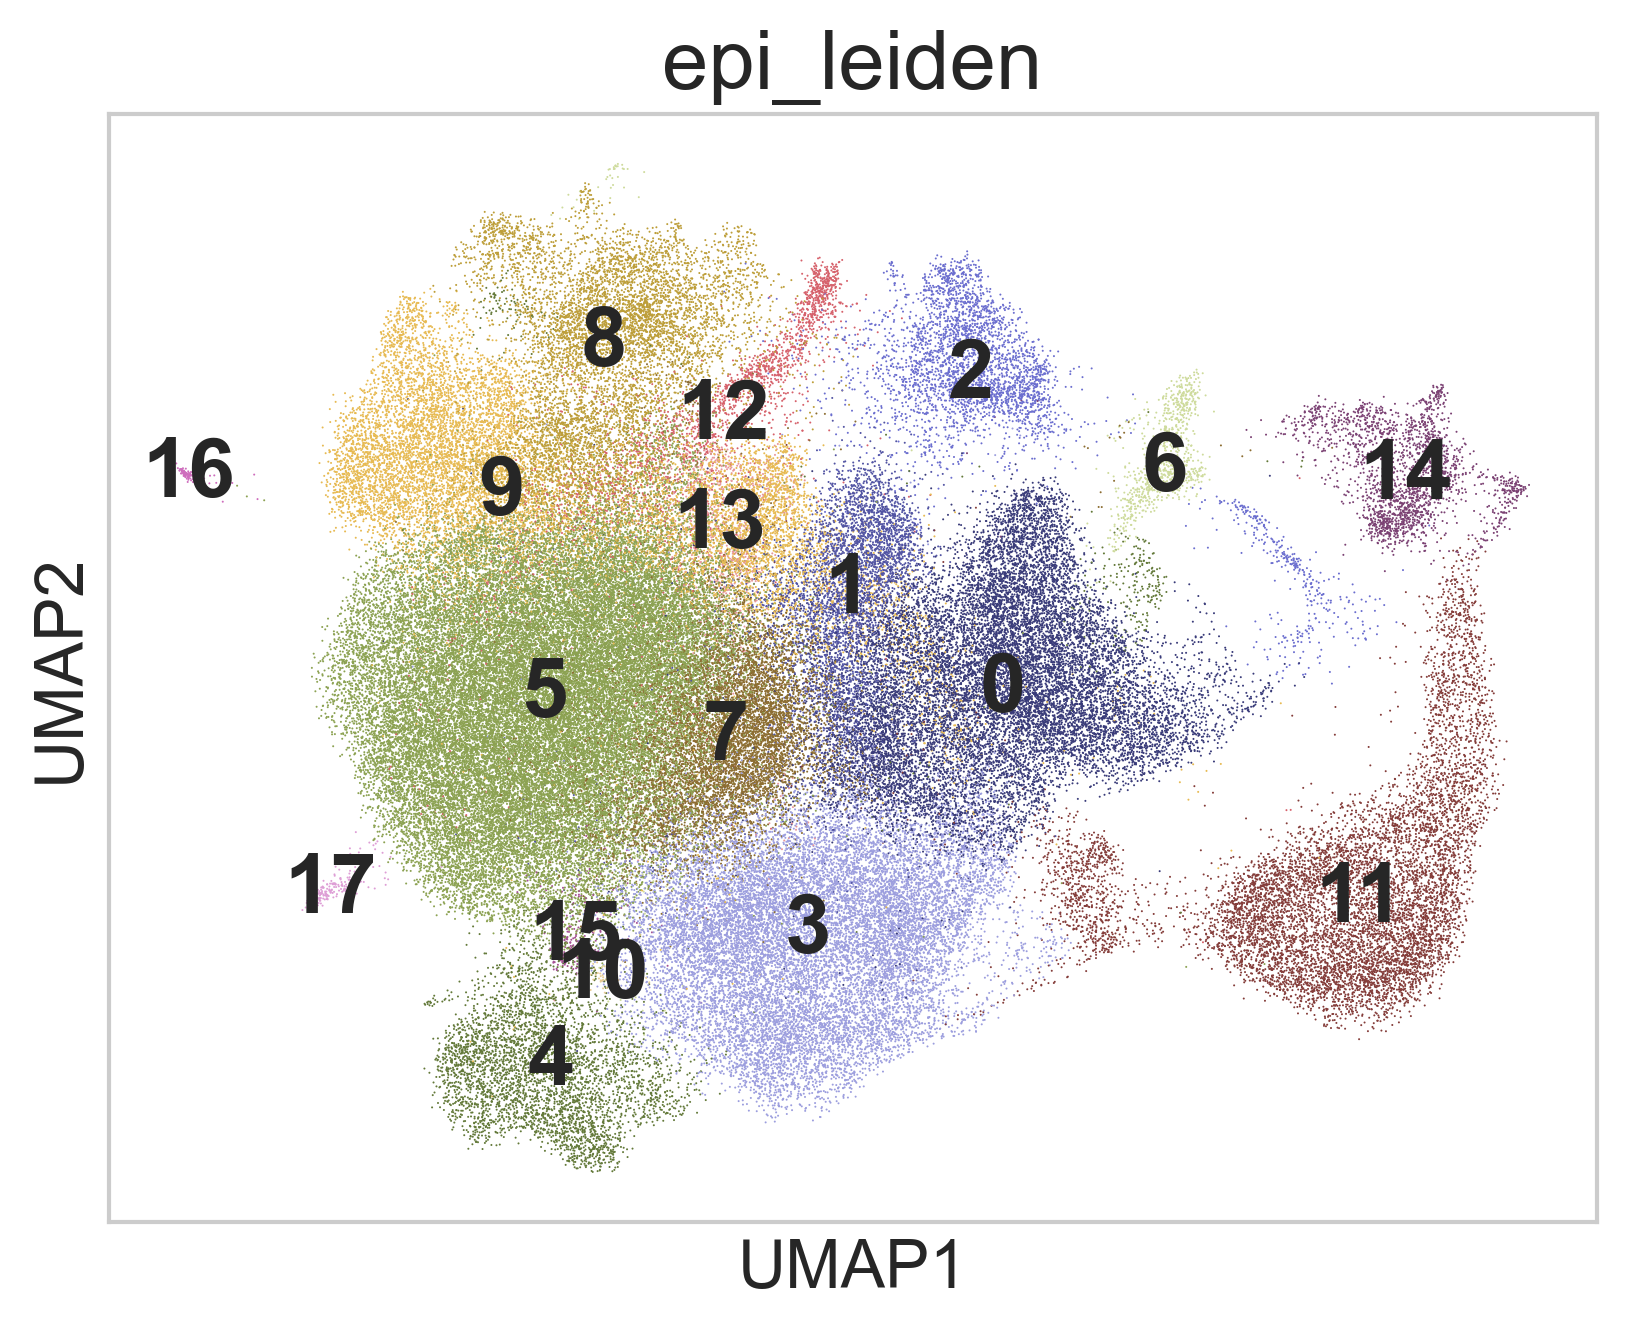

In [31]:
sc.pl.umap(epi, color="epi_leiden", palette="tab20b",legend_loc="on data",)


/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


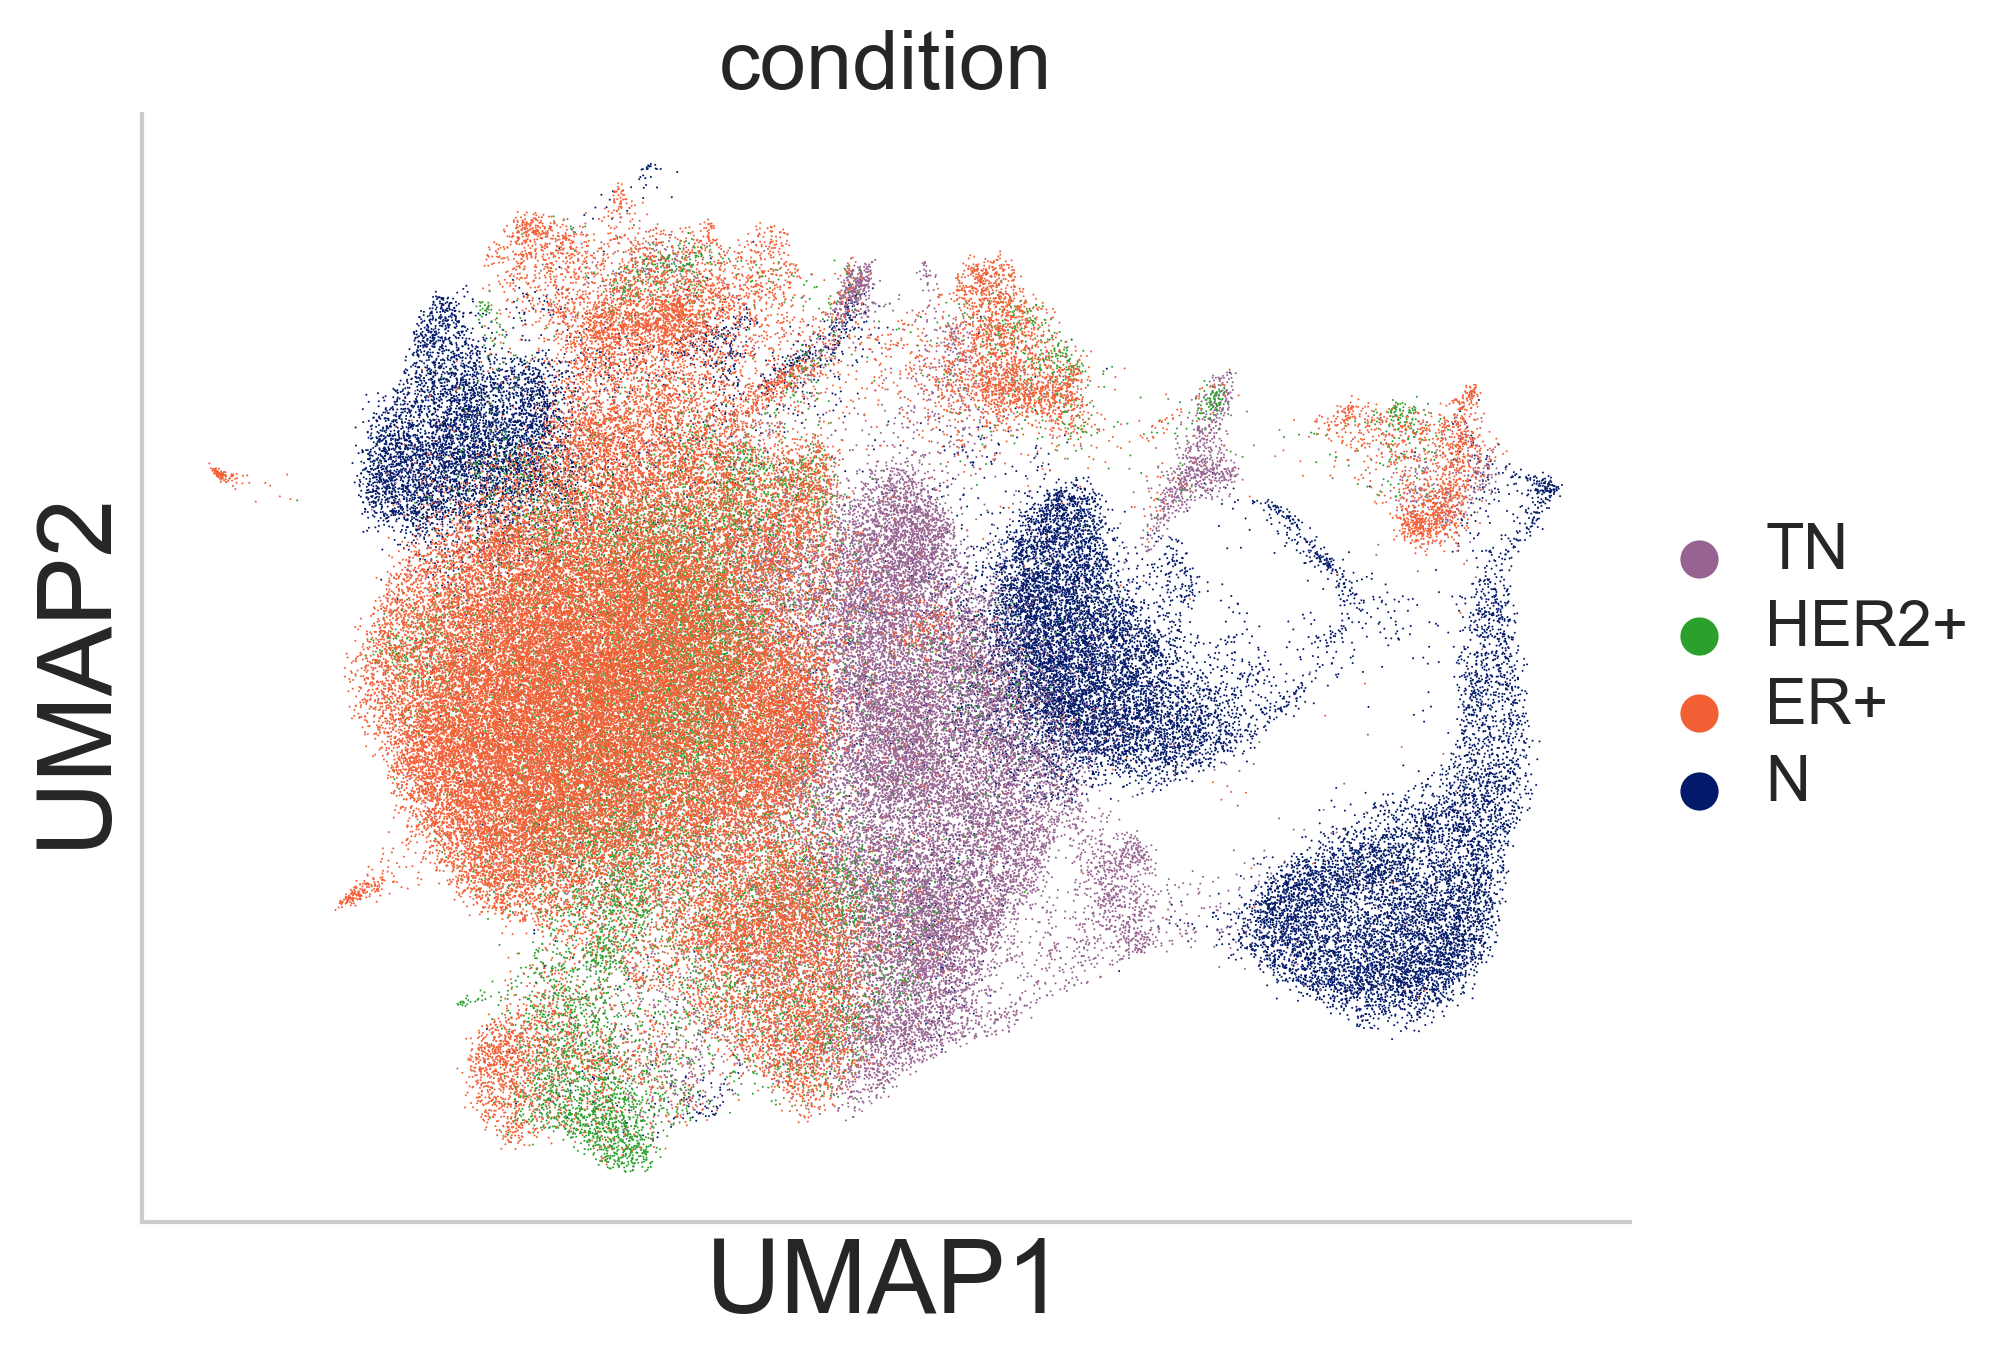

In [32]:
sc.pl.umap(
    epi[plot_idx],
    color="condition",
    palette=condition_palette,
    frameon=True,
    show=False,
)

ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)


ax.tick_params(axis="both", labelsize=12)

legend = ax.get_legend()


if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])


plt.savefig(fig_dir / "epithelial_umap_condition.png", dpi=300, bbox_inches="tight")
plt.show()


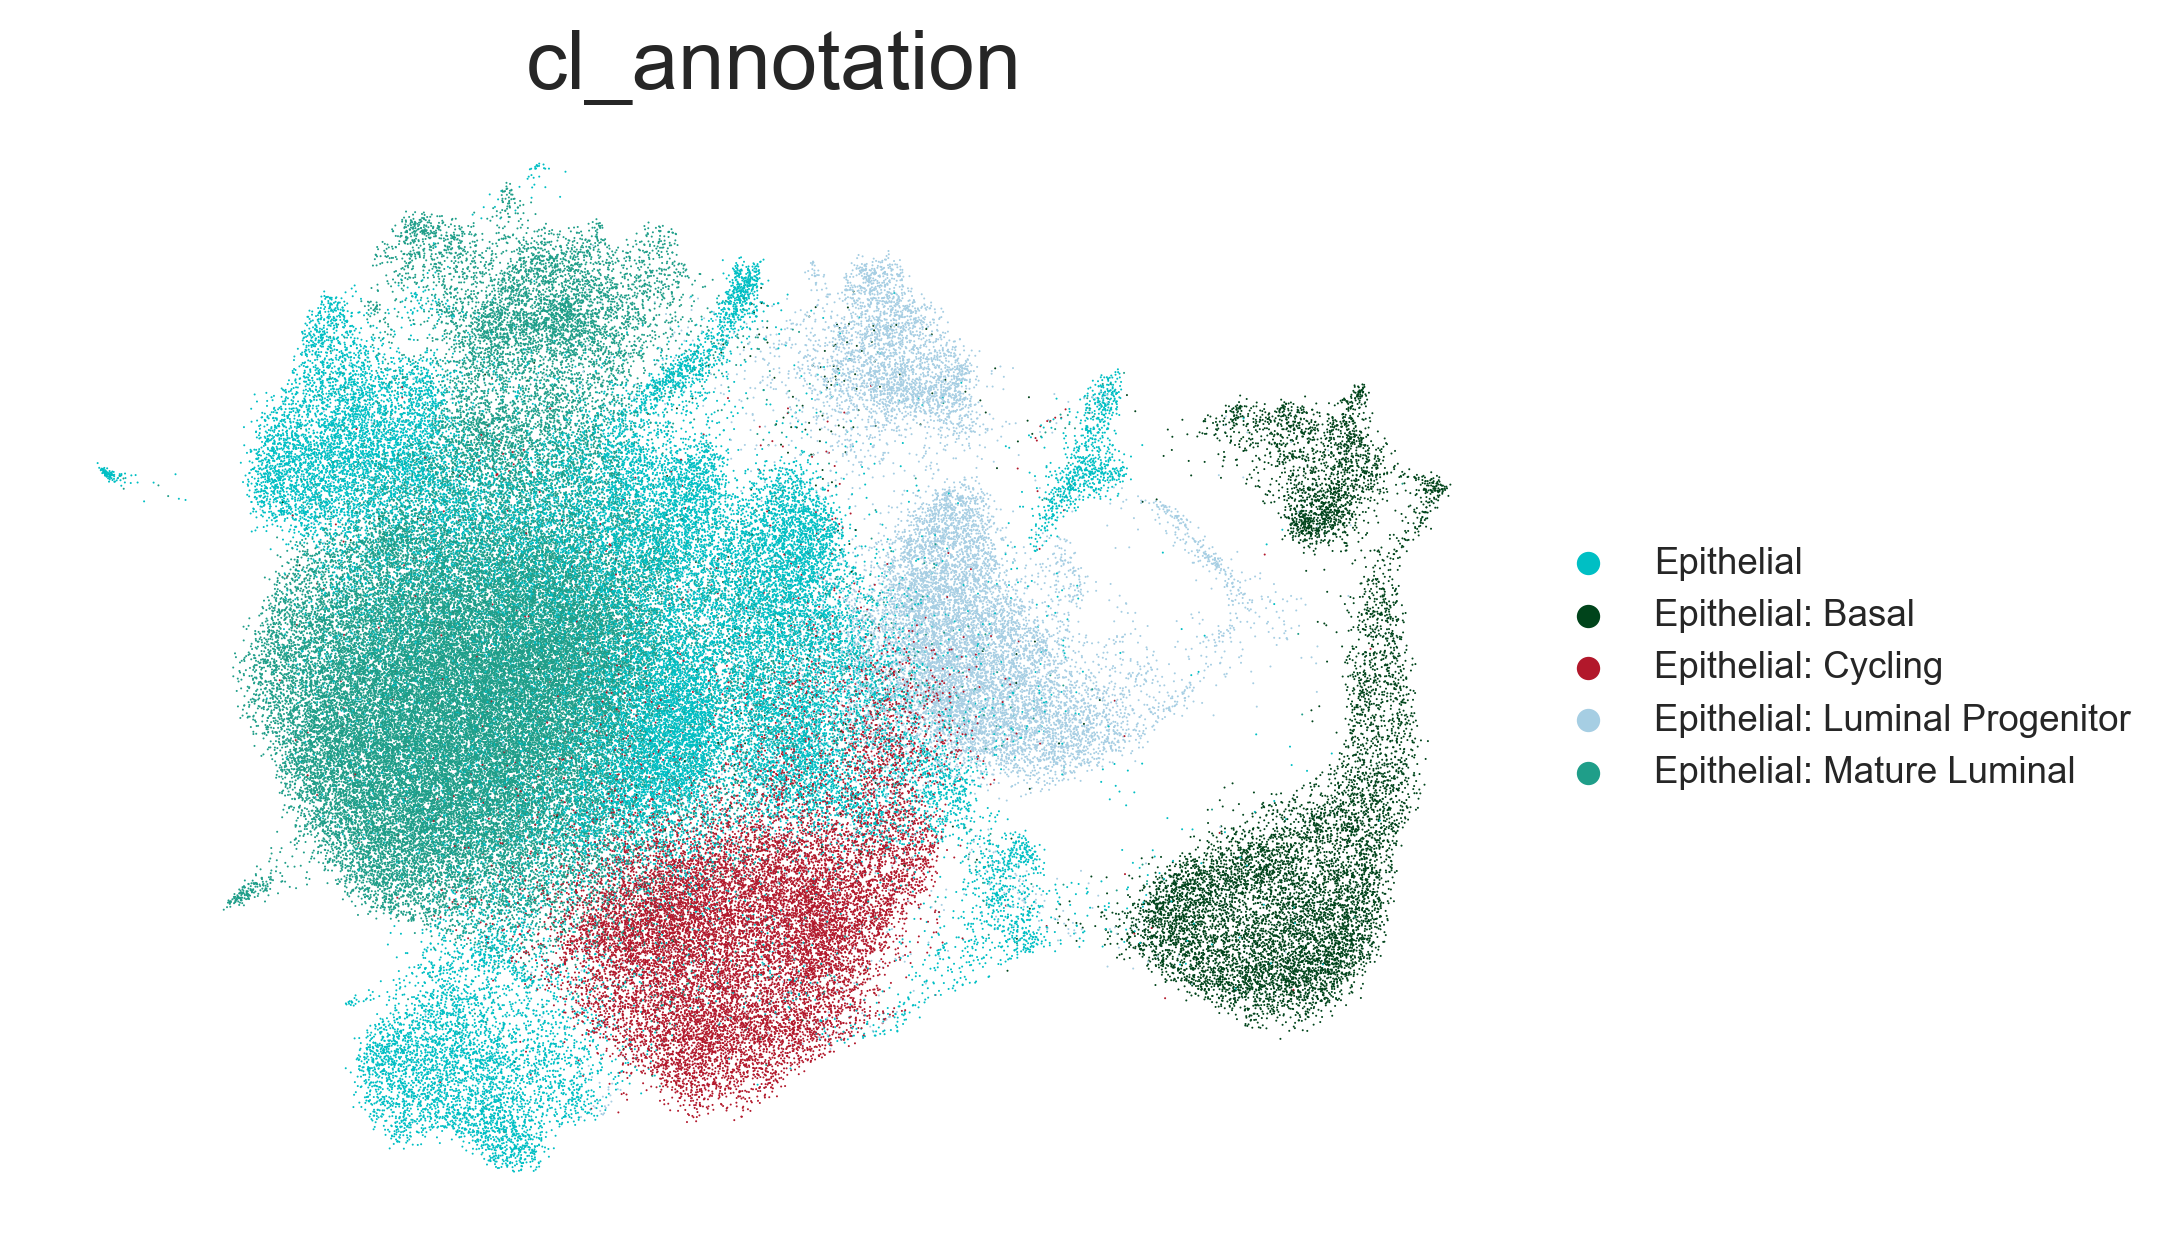

In [33]:
sc.pl.umap(epi, color="cl_annotation", frameon=False, show=False)

plt.savefig(fig_dir / "epithelial_umap_cl_annotation.png", dpi=300, bbox_inches="tight")
plt.show()


In [34]:
# Exploratory marker ranking for epithelial clusters.
sc.tl.rank_genes_groups(
    epi,
    groupby="epi_leiden",
    layer="lognorm",
    use_raw=False,
    method="wilcoxon",
    pts=True,
    tie_correct=True,
)


ranking genes


KeyboardInterrupt: 

In [ ]:
cluster_markers = sc.get.rank_genes_groups_df(
    epi,
    group=None,
)

cluster_markers.to_csv(
    df_dir / "epithelial_cluster_markers_wilcoxon.csv",
    index=False,
)


In [ ]:
sc.pl.rank_genes_groups_dotplot(
    epi,
    groupby="epi_leiden",
    n_genes=5,
    values_to_plot="logfoldchanges",
    standard_scale="var",
    show=False,
)


plt.savefig(
    fig_dir / "epithelial_cluster_markers_top5.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [ ]:
# samples coloured individually, with the legend grouped by condition


sc.pl.umap(epi, color="sample_short", legend_loc=None, frameon=False, show=False)

ax = plt.gca()

# read the colours scanpy just assigned, so the legend matches the plot
sample_to_color = dict(
    zip(epi.obs["sample_short"].cat.categories, epi.uns["sample_short_colors"])
)

handles = []


for condition in condition_order:

    handles.append(Line2D([], [], linestyle="none", label=condition, color="black"))

    for sample in sorted(epi.obs.loc[epi.obs["condition"] == condition, "sample_short"].unique()):
        handles.append(
            Line2D([], [], marker="o", linestyle="none", markersize=6,
                   markerfacecolor=sample_to_color[sample], markeredgecolor="none",
                   label=f"  {sample}")
        )


ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=7)

plt.savefig(fig_dir / "epithelial_umap_sample.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
umap = epi.obsm["X_umap"]
tumour_derived_cnv_high_plot = epi.obs["tumour_derived_cnv_high"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sc.pl.umap(
    epi, color="cnv_score", color_map="viridis", vmax="p99.9",
    frameon=False, title="CNV burden", ax=axes[0], show=False,
)


axes[1].scatter(
    umap[:, 0], umap[:, 1], s=1, color="#D0D0D0",
    linewidths=0, rasterized=True,
)
axes[1].scatter(
    umap[tumour_derived_cnv_high_plot, 0], umap[tumour_derived_cnv_high_plot, 1], s=1, color="#D55E00",
    linewidths=0, rasterized=True,
)
axes[1].set_title("CNV-high tumour-derived epithelium")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_aspect("equal", adjustable="datalim")


axes[1].set_frame_on(False)
axes[1].legend(
    handles=[
        Line2D([], [], marker="o", linestyle="none", color="#D0D0D0", label="other epithelium"),
        Line2D([], [], marker="o", linestyle="none", color="#D55E00", label="CNV-high tumour-derived"),
    ],
    frameon=False, loc="lower left", markerscale=3, fontsize=8,
)


sc.pl.umap(
    epi, color="epi_leiden", legend_loc="right margin",
    frameon=False, title="Epithelial clusters", ax=axes[2], show=False,
)

fig.tight_layout()
fig.savefig(
    fig_dir / "epithelial_umap_population_and_cnv.svg",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [ ]:
import sys
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
from scripts.publication_figure_state import save_cnv_panels

save_cnv_panels(epi, fig_dir)

In [ ]:
sc.pl.umap(epi, color='cnv_score', color_map='viridis', frameon=False, show=False, vmax='p99.9')


In [ ]:
sc.pl.umap(epi, color='cnv_score', color_map='RdYlBu_r', frameon=False, show=False, vmax='p99.9')


In [ ]:
origin_palette = {
    "normal-tissue epithelium": "#56B4E9",
    "tumour-derived epithelium": "#D55E00",
}


In [ ]:
sc.pl.umap(
    epi,
    color="specimen_origin",
    palette=origin_palette,
    frameon=False,
    show=False,
    title="Epithelial cells by specimen origin",
)
plt.savefig(
    fig_dir / "epithelial_umap_specimen_origin.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## Feature-set sensitivity


The primary scVI model uses only the deviance-ranked genes. A second model adds
the antigen and meta-programme genes to test whether that targeted feature choice changes
the neighbourhood or cluster structure beyond ordinary run-to-run variation.


In [ ]:
epi_protected = epi[:, epi.var["highly_variable_protected"]].copy()
assert epi_protected.n_vars == n_hvg_protected


In [ ]:
scvi.model.SCVI.setup_anndata(
    epi_protected, layer="counts", batch_key="sample"
)


In [ ]:
model_protected = scvi.model.SCVI(
    epi_protected,
    n_latent=n_latent,
    n_layers=n_layers,
    gene_likelihood=gene_likelihood,
)


In [ ]:
model_protected.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)


In [ ]:
epi.obsm["X_scVI_protected"] = model_protected.get_latent_representation()


In [ ]:
del model_protected
gc.collect()


In [ ]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI_protected",
    n_neighbors=n_neighbors,
    random_state=random_seed,
    key_added="protected_neighbors",
)


In [ ]:
sc.tl.leiden(
    epi,
    resolution=primary_resolution,
    key_added="epi_leiden_protected",
    neighbors_key="protected_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=random_seed,
)

del epi_protected


In [ ]:
gc.collect()


In [ ]:
epi_seed = epi[:, epi.var["highly_variable"]].copy()
scvi.settings.seed = random_seed + 1
scvi.model.SCVI.setup_anndata(epi_seed, layer="counts", batch_key="sample")
 


In [ ]:
model_seed = scvi.model.SCVI(
    epi_seed,
    n_latent=n_latent,
    n_layers=n_layers,
    gene_likelihood=gene_likelihood,
)


In [ ]:
model_seed.train(
    max_epochs=400,
    accelerator="mps",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)

epi.obsm["X_scVI_seed2"] = model_seed.get_latent_representation()
scvi.settings.seed = random_seed


In [ ]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI_seed2",
    n_neighbors=n_neighbors,
    random_state=random_seed,
    key_added="seed2_neighbors",
)


In [ ]:
sc.tl.leiden(
    epi,
    resolution=primary_resolution,
    key_added="epi_leiden_seed2",
    neighbors_key="seed2_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=random_seed,
)

del epi_seed, model_seed


In [ ]:
gc.collect()


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors


In [ ]:
k_overlap = n_neighbors
overlap_idx = eval_idx


In [ ]:
def knn_indices(representation):
    values = epi.obsm[representation][overlap_idx]
    model_nn = NearestNeighbors(n_neighbors=k_overlap + 1).fit(values)
    return model_nn.kneighbors(values, return_distance=False)[:, 1:]


In [ ]:
primary_neighbors = knn_indices("X_scVI")
comparisons = [
    ("protected feature set", "X_scVI_protected", "epi_leiden_protected"),
    ("different seed", "X_scVI_seed2", "epi_leiden_seed2"),
]

rows = []


In [ ]:
for label, representation, clustering in comparisons:
    other_neighbors = knn_indices(representation)
    overlap = np.array([
        len(set(left) & set(right)) / k_overlap
        for left, right in zip(primary_neighbors, other_neighbors)
    ])
    rows.append({
        "comparison": label,
        "leiden_ari": adjusted_rand_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "leiden_nmi": normalized_mutual_info_score(epi.obs["epi_leiden"], epi.obs[clustering]),
        "knn_overlap_mean": overlap.mean(),
        "knn_overlap_median": np.median(overlap),
        "n_clusters": epi.obs[clustering].nunique(),
    })


In [ ]:
latent_comparison = pd.DataFrame(rows)
latent_comparison.to_csv(df_dir / "scvi_latent_comparison.csv", index=False)
display(latent_comparison.round(3))


In [ ]:
rows = []


In [ ]:
for label, representation in [
    ("primary_deviance", "X_scVI"),
    ("protected_sensitivity", "X_scVI_protected"),
    ("primary_second_seed", "X_scVI_seed2"),
]:
    values = epi.obsm[representation][eval_idx]
    rows.append({
        "model": label,
        "annotation_silhouette": silhouette_score(values, obs_eval["cl_annotation"]),
        "sample_silhouette": silhouette_score(values, obs_eval["sample"]),
        "condition_silhouette": silhouette_score(values, obs_eval["condition"].astype(str)),
    })


In [ ]:
model_comparison = pd.DataFrame(rows)
display(model_comparison.round(3))


In [ ]:
# free the large intermediates; nothing below uses them
del model
gc.collect()


In [ ]:
rows = []


In [ ]:
for annotation in obs_eval["cl_annotation"].value_counts().index:
    mask = obs_eval["cl_annotation"].eq(annotation).to_numpy()
    if mask.sum() < 100 or obs_eval.loc[mask, "sample"].nunique() < 2:
        continue

    row = {"cl_annotation": annotation, "n_cells": int(mask.sum())}
    for label, representation in [
        ("primary_deviance", "X_scVI"),
        ("protected_sensitivity", "X_scVI_protected"),
        ("primary_second_seed", "X_scVI_seed2"),
    ]:
        row[label] = silhouette_score(
            epi.obsm[representation][eval_idx][mask],
            obs_eval.loc[mask, "sample"],
        )
    rows.append(row)


In [ ]:
within_annotation = pd.DataFrame(rows)
display(within_annotation.round(3))


In [ ]:
cluster_overlap = pd.crosstab(
    epi.obs["epi_leiden"], epi.obs["epi_leiden_protected"]
)
best_match = cluster_overlap.max(axis=1) / cluster_overlap.sum(axis=1)

feature_effect = latent_comparison.iloc[0]
seed_floor = latent_comparison.iloc[1]


In [ ]:
epi.uns["protected_gene_sensitivity"] = {
    "primary_features": int(n_hvg_deviance),
    "protected_features": int(n_hvg_protected),
    "protected_added": int(n_protected_added),
    "feature_set_ari": float(feature_effect["leiden_ari"]),
    "seed_floor_ari": float(seed_floor["leiden_ari"]),
    "feature_set_knn_overlap": float(feature_effect["knn_overlap_mean"]),
    "seed_floor_knn_overlap": float(seed_floor["knn_overlap_mean"]),
    "k": int(k_overlap),
}

model_comparison.to_csv(df_dir / "scvi_feature_sensitivity.csv", index=False)


In [ ]:
within_annotation.to_csv(
    df_dir / "scvi_feature_sensitivity_by_annotation.csv", index=False
);


In [ ]:
best_match.rename("largest_matching_fraction").to_csv(
    df_dir / "scvi_feature_cluster_correspondence.csv"
)


## Save

In [ ]:
final_positive = {
    gene: int((np.asarray(epi[:, gene].layers["counts"].todense()).ravel() > 0).sum())
    for gene in target_genes
}

assert epi.n_obs == n_cells_start
assert epi.n_vars == n_genes_start
assert final_positive == {gene: baseline_positive[gene] for gene in final_positive}


In [ ]:
epi.uns["epithelial_integration"] = {
    "hvg_method": "binomial deviance (scry), maximum across samples",
    "primary_feature_set": "deviance-ranked genes only",
    "n_hvg_primary": int(n_hvg_deviance),
    "n_hvg_protected_sensitivity": int(n_hvg_protected),
    "scvi_n_latent": int(n_latent),
    "scvi_n_layers": int(n_layers),
    "scvi_gene_likelihood": gene_likelihood,
    "scvi_batch_key": "sample",
    "scvi_epochs": int(n_epochs),
    "n_neighbors": int(n_neighbors),
    "leiden_resolutions": [float(value) for value in leiden_resolutions],
    "leiden_primary": float(primary_resolution),
    "seed": int(random_seed),
}


In [ ]:
import sys
repository = find_publication()
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))
check_dir = repository / "results" / "publication_checks"
check_dir.mkdir(parents=True, exist_ok=True)

from scripts.publication_targeted_checks import barcode_audit

barcode_recovery = barcode_audit(epi, project, repository, check_dir)
barcode_recovery.loc[barcode_recovery["source_group_available"]]


Source barcode transfer audit. Recovery after QC is reported separately from sample identity; ER-MH0001 is excluded from transfer. This is optional concordance, not the primary specimen-origin definition.

In [ ]:
out_path = save_dir / "epithelial_tumour_scvi.h5ad"


In [ ]:
for name in list(epi.layers.keys()):
    if not sp.issparse(epi.layers[name]):
        epi.layers[name] = sp.csr_matrix(epi.layers[name])


In [ ]:
if not sp.issparse(epi.X):
    epi.X = sp.csr_matrix(epi.X)


In [ ]:
if not epi.uns.get("figure_only", False):
    # Write safely before replacing the existing file.
    tmp_path = out_path.with_suffix(".h5ad.tmp")
    epi.write_h5ad(tmp_path, compression="gzip")
    os.replace(tmp_path, out_path)

    display(pd.DataFrame({"saved": [out_path.name]}))

In [ ]:
check = sc.read_h5ad(out_path, backed="r")

assert check.n_obs == epi.n_obs
assert check.n_vars == epi.n_vars


In [ ]:
check.shape


In [ ]:
del check
gc.collect()


In [ ]:
import session_info


In [ ]:
session_info.show()
